In [4]:
# Notebook 04 — Entropy
#
# Objective:
# - Measure price-pattern uncertainty and regularity.
# - Measure additional information from spread evolution.
# - Save decimal scores, descriptive labels and support counts.
#
# Prerequisites:
# - Completed Notebook 02 run: sampling_02_v1.
# - Existing Notebook 03 helper utilities.
# - Existing Python environment; no additional libraries.
#
# Inputs:
# - data/processed/sampling_02_v1/sampled_10s/YYYY-MM.parquet
# - Ten-second mids, spreads, availability times and quality flags.
#
# Agreed calculations:
# - Lookbacks: 3, 5, 15, 30 and 60 minutes.
# - Update every ten seconds.
# - Price symbols: down / unchanged / up.
# - Conditional entropy: uncertainty given the previous price symbol.
# - Sample entropy: two-change patterns, extended by one change.
# - Matching tolerance: 20% of the window's population standard deviation.
# - Spread input: change over the preceding five minutes.
# - Transfer entropy: previous spread-change symbol adds information
#   about the following price-change symbol, given the previous price symbol.
#
# Saved scores:
# - Conditional uncertainty: conditional entropy / log2(3).
# - Conditional diagnostic: conditional entropy / target-symbol entropy.
# - Sample irregularity: 1 - exp(-sample entropy).
# - Transfer information: transfer entropy / baseline conditional entropy.
# - Raw entropy values and support counts are retained.
#
# Labels:
# - Low: below 1/3.
# - Medium: from 1/3 to below 2/3.
# - High: from 2/3 to 1.
# - These are descriptive labels, not trading thresholds.
# - High transfer entropy means greater additional spread information.
#
# Missing data:
# - Restart after an unfilled gap or closure.
# - Require a fresh full lookback.
# - Available excluded-hour prices continue contributing.
# - Eligible interpolated prices remain included.
# - No matching sample-entropy patterns means unavailable, not zero.
#
# Timing:
# - Store UTC integer nanoseconds; display Europe/Athens.
# - Preserve upstream availability, including right-anchor delays.
# - Save separate availability times for each window and estimator.
# - A W-minute window contains W*6 price changes and W*6-1 transitions.
# - Three-minute transfer entropy first becomes ready after 7m50s.
#
# Numerical conventions:
# - Prices are USD per EUR; price changes are in pips.
# - One pip = 0.0001.
# - A 1e-8-pip tolerance handles floating-point comparison noise.
# - It is not an economically meaningful price deadband.
# - Sample-entropy matches use distance <= tolerance + numerical tolerance.
#
# Outputs:
# - outputs/features/entropy/entropy_04_v1/YYYY-MM-DD.parquet
# - Daily checkpoints support interrupted processing.
# - reports/tables/entropy/entropy_04_v1/
# - reports/figures/entropy/entropy_04_v1/
#
# Validation:
# - Synthetic patterns, independent and informative TE examples.
# - Exact sample-match counts against direct enumeration.
# - Restart, warm-up, availability and processing-boundary checks.
# - Saved-file reconciliation and score-range checks.
#
# Initial scope:
# - One day only.
# - Sample entropy is computationally expensive.
# - Review runtime before expanding processing.
#
# Future comparison:
# - After Notebook 06, compare no entropy and each entropy candidate.
# - Use a one-month development experiment and chronological evaluation.
# - Define success independently of the entropy being assessed.

In [5]:
# Environment and repository location.
# Run Jupyter from the repository or its notebooks folder.
# Set ROOT_HINT only if automatic discovery cannot find the repository.

from pathlib import Path
import importlib
import importlib.metadata
import json
import os
import sys

ROOT_HINT = None

candidates = (
    [Path(ROOT_HINT).expanduser().resolve()]
    if ROOT_HINT
    else [Path.cwd(), *Path.cwd().parents]
)

ROOT = next(
    (
        path for path in candidates
        if (path / "functions" / "sampling" / "market_series.py").is_file()
        and (path / "data").is_dir()
    ),
    None,
)

assert ROOT is not None, (
    "Repository not found. Set ROOT_HINT to the repository folder."
)

ROOT = ROOT.resolve()
os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

libraries = ["numpy", "pandas", "pyarrow", "duckdb", "matplotlib"]

environment = {
    "python": sys.version.split()[0],
    **{
        name: importlib.metadata.version(name)
        for name in libraries
    },
}

print("Repository:", ROOT)
print(json.dumps(environment, indent=2))

assert (
    ROOT / "functions" / "volatility" / "multiscale_volatility.py"
).is_file(), "Notebook 03 helper is required."

(ROOT / "functions" / "entropy").mkdir(parents=True, exist_ok=True)

Repository: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator
{
  "python": "3.14.8",
  "numpy": "2.5.4",
  "pandas": "3.0.6",
  "pyarrow": "26.0.0",
  "duckdb": "2.0.0",
  "matplotlib": "3.11.2"
}


In [6]:
%%writefile functions/entropy/market_entropy.py
import hashlib
import json
import time
from collections import deque
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

from functions.etl import clean_quotes as fx
from functions.volatility import multiscale_volatility as utilities

NS = 1_000_000_000
STEP = 10 * NS
PIP = 0.0001

WINDOWS = {"3m": 18, "5m": 30, "15m": 90, "30m": 180, "60m": 360}
SPREAD_STEPS = 30
MAX_PRIOR = max(WINDOWS.values()) + SPREAD_STEPS - 1

MATCH_ATOL = 1e-8
ENTROPY_ATOL = 1e-10

SOURCE_RUN = "sampling_02_v1"
SOURCE_FP = (
    "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54"
)

SOURCE_COLUMNS = [
    "sample_ns", "available_ns", "mid", "spread",
    "has_price", "is_interpolated", "in_long_gap",
    "project_excluded", "project_eligible",
]


def dependencies():
    return {
        "entropy_helper": utilities.sha(__file__),
        "utility_helper": utilities.sha(utilities.__file__),
        "etl_helper": utilities.sha(fx.__file__),
    }


def prepare(root, run_id, stop_after_date, memory="2GB", threads=2):
    root = Path(root).resolve()
    assert run_id and Path(run_id).name == run_id

    source = root / "data" / "processed" / SOURCE_RUN
    reports = root / "reports" / "tables" / "sampling" / SOURCE_RUN

    source_config = fx.load_json(source / "configuration.json")
    source_state = fx.load_json(source / "run_state.json")
    source_summary = fx.load_json(reports / "execution_summary.json")
    completion = fx.load_json(reports / "full_history_completion_checks.json")

    assert source_state["fingerprint"] == SOURCE_FP
    assert source_state["status"] == "full_history_processed"
    assert source_summary["fingerprint"] == SOURCE_FP
    assert source_summary["full_history_complete"]
    assert source_summary["nonzero_machine_checks"] == 0
    assert completion["fingerprint"] == SOURCE_FP
    assert completion["machine_checks_passed"]
    assert all(completion["checks"].values())

    first_real = int(source_config["inputs"][0]["first_ns"])
    last_real = int(source_config["inputs"][-1]["last_ns"])

    inputs = []
    for checkpoint_path in sorted((source / "_checkpoints").glob("*.json")):
        month = checkpoint_path.stem
        checkpoint = fx.load_json(checkpoint_path)

        assert checkpoint["fingerprint"] == SOURCE_FP
        assert all(value == 0 for value in checkpoint["checks"].values())

        path = source / "sampled_10s" / f"{month}.parquet"
        actual = utilities.file_info(path)
        expected = checkpoint["outputs"]["sampled_10s"]

        assert all(actual[key] == expected[key] for key in actual), path

        schema = pq.read_schema(path)
        assert set(SOURCE_COLUMNS).issubset(schema.names), path
        for name in ("sample_ns", "available_ns"):
            assert pa.types.is_int64(schema.field(name).type), (path, name)
        for name in ("mid", "spread"):
            assert pa.types.is_floating(schema.field(name).type), (path, name)

        lower, upper = fx.month_bounds(month)
        first = max(lower, ((first_real + STEP - 1) // STEP) * STEP)
        last = min(upper - STEP, (last_real // STEP) * STEP)

        assert actual["rows"] == (last - first) // STEP + 1

        inputs.append({
            "year_month": month,
            "path": path.relative_to(root).as_posix(),
            **actual,
            "first_ns": first,
            "last_ns": last,
            "checkpoint_path": checkpoint_path.relative_to(root).as_posix(),
            "checkpoint_sha256": utilities.sha(checkpoint_path),
        })

    months = [item["year_month"] for item in inputs]
    assert months == [
        str(period)
        for period in pd.period_range(months[0], months[-1], freq="M")
    ]
    assert len(inputs) == source_summary["processed_months"]
    assert sum(item["rows"] for item in inputs) == source_summary["sample_rows"]

    first = pd.Timestamp(inputs[0]["first_ns"], unit="ns", tz="UTC")
    last = pd.Timestamp(inputs[-1]["last_ns"], unit="ns", tz="UTC")
    first = first.tz_convert("Europe/Athens")
    last = last.tz_convert("Europe/Athens")

    jobs = []
    for day in pd.date_range(first.normalize(), last.normalize(), freq="D"):
        lower = max(int(day.value), inputs[0]["first_ns"])
        upper = min(
            int((day + pd.DateOffset(days=1)).value),
            inputs[-1]["last_ns"] + STEP,
        )
        if lower < upper:
            jobs.append({
                "date": day.strftime("%Y-%m-%d"),
                "lower_ns": lower,
                "upper_ns": upper,
                "rows": (upper - lower) // STEP,
            })

    if stop_after_date is not None:
        assert stop_after_date in [item["date"] for item in jobs]

    run = root / "outputs" / "features" / "entropy" / run_id
    tables = root / "reports" / "tables" / "entropy" / run_id
    figures = root / "reports" / "figures" / "entropy" / run_id

    configuration = {
        "definition": "entropy_v1",
        "run_id": run_id,
        "source_run": SOURCE_RUN,
        "source_fingerprint": SOURCE_FP,
        "source_configuration_sha256": utilities.sha(source / "configuration.json"),
        "source_contract_sha256": utilities.sha(source / "output_contract.json"),
        "dependencies": dependencies(),
        "versions": utilities.versions(),
        "inputs": inputs,
        "step_seconds": 10,
        "windows_changes": WINDOWS,
        "spread_change_seconds": 300,
        "price_symbols": "down, unchanged, up",
        "conditional_history_symbols": 1,
        "conditional_score": "H(current|previous)/log2(3)",
        "conditional_diagnostic": "H(current|previous)/H(current); zero if constant",
        "sample_pattern_length": 2,
        "sample_tolerance_fraction": 0.2,
        "sample_sd": "population, ddof=0, within current trailing window",
        "sample_common_template_starts": "0 through N-3",
        "sample_self_matches": False,
        "sample_overlapping_templates": True,
        "sample_score": "1-A/B; missing if B=0",
        "transfer_source": "previous five-minute spread-change sign",
        "transfer_target": "following ten-second price-change sign",
        "transfer_condition": "previous ten-second price-change sign",
        "transfer_score": "TE/H(current price sign|previous price sign)",
        "transfer_zero_denominator": "missing with flag",
        "full_fresh_window_after_missing": True,
        "excluded_hours_with_prices_continue": True,
        "interpolation_eligible": True,
        "comparison_tolerance_pips": MATCH_ATOL,
        "entropy_roundoff_tolerance": ENTROPY_ATOL,
        "label_boundaries": [1 / 3, 2 / 3],
        "learned_thresholds": False,
        "pip_size": PIP,
    }

    fingerprint = hashlib.sha256(
        json.dumps(
            configuration, sort_keys=True, separators=(",", ":")
        ).encode("utf-8")
    ).hexdigest()

    for directory in (run, tables, figures, run / "_checkpoints"):
        directory.mkdir(parents=True, exist_ok=True)

    config_path = run / "configuration.json"
    if config_path.exists():
        existing = fx.load_json(config_path)
        changed = [
            key for key in sorted(set(existing) | set(configuration))
            if existing.get(key) != configuration.get(key)
        ]
        assert not changed, (
            f"Configuration changed in {changed}. Use a new RUN_ID."
        )
    else:
        fx.dump_json(config_path, configuration)

    pd.DataFrame(inputs).to_csv(tables / "input_inventory.csv", index=False)

    return {
        "root": root, "run": run, "tables": tables, "figures": figures,
        "run_id": run_id, "fingerprint": fingerprint,
        "configuration": configuration, "inputs": inputs, "jobs": jobs,
        "target_jobs": [
            job for job in jobs
            if stop_after_date is None or job["date"] <= stop_after_date
        ],
        "memory": memory, "threads": threads,
    }


def check_snapshot(ctx):
    source = ctx["root"] / "data" / "processed" / SOURCE_RUN
    config = ctx["configuration"]

    assert dependencies() == config["dependencies"]
    assert utilities.versions() == config["versions"]
    assert utilities.sha(source / "configuration.json") == (
        config["source_configuration_sha256"]
    )
    assert utilities.sha(source / "output_contract.json") == (
        config["source_contract_sha256"]
    )

    for item in ctx["inputs"]:
        actual = utilities.file_info(ctx["root"] / item["path"])
        assert all(actual[key] == item[key] for key in actual), item["path"]
        assert utilities.sha(ctx["root"] / item["checkpoint_path"]) == (
            item["checkpoint_sha256"]
        )

Overwriting functions/entropy/market_entropy.py


In [7]:
%%writefile -a functions/entropy/market_entropy.py


def values(table, name, fill=None):
    column = table[name]
    if fill is not None:
        column = column.fill_null(fill)
    return column.to_numpy(zero_copy_only=False)


def arrow(values_array, valid=None):
    return pa.array(
        values_array,
        mask=None if valid is None else ~valid,
        from_pandas=True,
    )


def symbols(changes):
    result = np.full(len(changes), -1, dtype=np.int8)
    valid = np.isfinite(changes)
    result[valid] = np.sign(changes[valid]).astype(np.int8) + 1
    result[valid & (np.abs(changes) <= MATCH_ATOL)] = 1
    return result


def labels(score):
    result = np.full(len(score), "unavailable", dtype=object)
    valid = np.isfinite(score)
    result[valid & (score < 1 / 3)] = "low"
    result[valid & (score >= 1 / 3) & (score < 2 / 3)] = "medium"
    result[valid & (score >= 2 / 3)] = "high"
    return result


def rolling_sum(data, width):
    cumulative = np.r_[0, np.cumsum(data, dtype=np.int64)]
    end = np.arange(1, len(data) + 1)
    return cumulative[end] - cumulative[np.maximum(0, end - width)]


def rolling_counts(ids, categories, width):
    data = np.zeros((len(ids), categories), dtype=np.int64)
    valid = ids >= 0
    data[np.flatnonzero(valid), ids[valid]] = 1
    cumulative = np.vstack([
        np.zeros((1, categories), dtype=np.int64),
        np.cumsum(data, axis=0),
    ])
    end = np.arange(1, len(ids) + 1)
    return cumulative[end] - cumulative[np.maximum(0, end - width)]


def rolling_max_integer(data, width):
    result = np.empty(len(data), dtype=np.int64)
    queue = deque()
    for index, value in enumerate(data):
        while queue and queue[0] <= index - width:
            queue.popleft()
        while queue and data[queue[-1]] <= value:
            queue.pop()
        queue.append(index)
        result[index] = data[queue[0]]
    return result


def entropy(counts):
    counts = np.asarray(counts, dtype=np.float64)
    total = counts.sum(axis=-1)
    log_counts = np.zeros_like(counts)
    np.log2(counts, out=log_counts, where=counts > 0)

    result = np.zeros_like(total)
    valid = total > 0
    result[valid] = (
        np.log2(total[valid])
        - (counts * log_counts).sum(axis=-1)[valid] / total[valid]
    )
    assert np.all(result >= -ENTROPY_ATOL)
    return np.maximum(result, 0)


def conditional_statistics(counts):
    joint = entropy(counts.reshape(len(counts), -1))
    previous = entropy(counts.sum(axis=2))
    target = entropy(counts.sum(axis=1))
    conditional = joint - previous

    assert np.all(conditional >= -ENTROPY_ATOL)
    assert np.all(conditional <= target + ENTROPY_ATOL)
    return np.maximum(conditional, 0), target


def transfer_statistics(cube):
    baseline, _ = conditional_statistics(cube.sum(axis=2))
    joint = entropy(cube.reshape(len(cube), -1))
    context = entropy(cube.sum(axis=3).reshape(len(cube), -1))
    with_spread = joint - context
    transfer = baseline - with_spread

    assert np.all(with_spread >= -ENTROPY_ATOL)
    assert np.all(transfer >= -ENTROPY_ATOL)
    assert np.all(transfer <= baseline + ENTROPY_ATOL)
    return baseline, np.maximum(transfer, 0)


def bounded(score):
    valid = np.isfinite(score)
    assert np.all(score[valid] >= -ENTROPY_ATOL)
    assert np.all(score[valid] <= 1 + ENTROPY_ATOL)
    result = score.copy()
    result[valid] = np.clip(result[valid], 0, 1)
    return result


def sample_counts(changes, tolerance):
    # Exact matching with first-coordinate candidate pruning.
    # Duplicate templates retain their full pair multiplicities.
    changes = np.asarray(changes, dtype=np.float64)
    assert changes.ndim == 1 and np.isfinite(changes).all()
    assert np.isfinite(tolerance) and tolerance >= 0

    templates = np.lib.stride_tricks.sliding_window_view(changes, 3)
    points, multiplicity = np.unique(
        templates, axis=0, return_counts=True
    )
    multiplicity = multiplicity.astype(np.int64, copy=False)

    order = np.argsort(points[:, 0], kind="stable")
    points = points[order]
    multiplicity = multiplicity[order]

    internal = int(np.sum(multiplicity * (multiplicity - 1) // 2))
    B = A = internal
    groups = len(points)

    if groups > 1:
        limit = float(tolerance) + MATCH_ATOL
        first = points[:, 0]
        scale = max(1.0, float(np.max(np.abs(first))), abs(limit))
        padding = 8 * np.finfo(np.float64).eps * scale

        upper = np.searchsorted(
            first,
            np.nextafter(first + limit + padding, np.inf),
            side="right",
        )
        index = np.arange(groups, dtype=np.int64)
        counts = np.maximum(upper - index - 1, 0)
        total = int(counts.sum())

        if total:
            left = np.repeat(index, counts)
            segment_start = np.cumsum(counts) - counts
            offset = np.arange(total) - np.repeat(segment_start, counts)
            right = left + 1 + offset
            weights = multiplicity[left] * multiplicity[right]

            match_two = (
                (np.abs(points[left, 0] - points[right, 0]) <= limit)
                & (np.abs(points[left, 1] - points[right, 1]) <= limit)
            )
            match_three = (
                match_two
                & (np.abs(points[left, 2] - points[right, 2]) <= limit)
            )

            B += int(weights[match_two].sum())
            A += int(weights[match_three].sum())

    maximum = len(templates) * (len(templates) - 1) // 2
    assert 0 <= A <= B <= maximum
    return B, A

Appending to functions/entropy/market_entropy.py


In [8]:
%%writefile -a functions/entropy/market_entropy.py


def compute(source):
    ts = values(source, "sample_ns")
    available = values(source, "available_ns")
    mid = values(source, "mid")
    spread = values(source, "spread")

    has = values(source, "has_price", False).astype(bool)
    interpolated = values(source, "is_interpolated", False).astype(bool)
    excluded = values(source, "project_excluded", False).astype(bool)
    eligible = values(source, "project_eligible", False).astype(bool)
    long_gap = values(source, "in_long_gap", False).astype(bool)

    checks = {
        "duplicate_input_times": len(ts) - len(np.unique(ts)),
        "broken_input_grid": int(np.count_nonzero(np.diff(ts) != STEP)),
        "invalid_input_timing": int(np.count_nonzero(
            (available < ts) | (ts % STEP != 0)
        )),
        "missing_required_input_fields": sum(
            source[name].null_count
            for name in (
                "sample_ns", "available_ns", "has_price",
                "in_long_gap", "project_excluded", "project_eligible",
            )
        ),
        "invalid_present_prices": int(np.count_nonzero(
            has & (
                ~np.isfinite(mid) | (mid <= 0)
                | ~np.isfinite(spread) | (spread < -MATCH_ATOL * PIP)
            )
        )),
        "missing_interpolation_flags": int(np.count_nonzero(
            has & source["is_interpolated"].is_null().to_numpy()
        )),
        "prices_on_missing_rows": int(np.count_nonzero(
            ~has & source["mid"].is_valid().to_numpy()
        )),
        "prices_inside_long_gaps": int(np.count_nonzero(has & long_gap)),
        "inconsistent_project_scope": int(np.count_nonzero(
            eligible & (~has | excluded)
        )),
    }
    assert all(value == 0 for value in checks.values()), checks

    index = np.arange(len(ts))
    last_missing = np.maximum.accumulate(np.where(has, -1, index))
    fresh = np.where(has, index - last_missing - 1, 0)

    change = np.full(len(ts), np.nan)
    change[1:] = (mid[1:] - mid[:-1]) / PIP
    change[fresh == 0] = np.nan
    change[np.isfinite(change) & (np.abs(change) <= MATCH_ATOL)] = 0

    spread_change = np.full(len(ts), np.nan)
    spread_change[SPREAD_STEPS:] = (
        spread[SPREAD_STEPS:] - spread[:-SPREAD_STEPS]
    ) / PIP
    spread_change[fresh < SPREAD_STEPS] = np.nan
    spread_change[
        np.isfinite(spread_change)
        & (np.abs(spread_change) <= MATCH_ATOL)
    ] = 0

    price_symbol = symbols(change)
    spread_symbol = symbols(spread_change)
    previous_price = np.r_[-1, price_symbol[:-1]]
    previous_spread = np.r_[-1, spread_symbol[:-1]]

    ce_id = np.full(len(ts), -1, dtype=np.int64)
    valid = (price_symbol >= 0) & (previous_price >= 0)
    ce_id[valid] = previous_price[valid] * 3 + price_symbol[valid]

    te_id = np.full(len(ts), -1, dtype=np.int64)
    valid = valid & (previous_spread >= 0)
    te_id[valid] = (
        previous_price[valid] * 9
        + previous_spread[valid] * 3
        + price_symbol[valid]
    )

    interpolated_change = (
        np.isfinite(change)
        & (interpolated | np.r_[False, interpolated[:-1]])
    )

    output = {
        name: source[name]
        for name in SOURCE_COLUMNS
        if name != "available_ns"
    }
    output.update({
        "input_available_ns": source["available_ns"],
        "available_ns": arrow(
            rolling_max_integer(available, MAX_PRIOR + 1)
        ),
        "change_10s_pips": arrow(change),
        "price_symbol": arrow(price_symbol, price_symbol >= 0),
        "spread_change_5m_pips": arrow(spread_change),
        "spread_change_5m_symbol": arrow(
            spread_symbol, spread_symbol >= 0
        ),
        "restart": arrow(has & (fresh == 0)),
        "fresh_changes_capped": arrow(np.minimum(fresh, MAX_PRIOR)),
    })

    timings = {}

    for key, n in WINDOWS.items():
        started = time.perf_counter()
        price_ready = fresh >= n
        te_ready = fresh >= n + SPREAD_STEPS - 1

        C = rolling_counts(ce_id, 9, n - 1).reshape(-1, 3, 3)
        h_conditional, h_target = conditional_statistics(C)

        ce_score = bounded(h_conditional / np.log2(3))
        residual = np.divide(
            h_conditional, h_target,
            out=np.zeros(len(ts)),
            where=h_target > ENTROPY_ATOL,
        )
        residual = bounded(residual)

        cube = rolling_counts(te_id, 27, n - 1).reshape(-1, 3, 3, 3)
        te_baseline, te_bits = transfer_statistics(cube)

        assert np.all(
            np.abs(te_baseline[te_ready] - h_conditional[te_ready])
            <= ENTROPY_ATOL
        )

        te_zero = te_baseline <= ENTROPY_ATOL
        te_fraction = np.divide(
            te_bits, te_baseline,
            out=np.full(len(ts), np.nan),
            where=te_ready & ~te_zero,
        )
        te_fraction = bounded(te_fraction)

        B = np.full(len(ts), -1, dtype=np.int64)
        A = np.full(len(ts), -1, dtype=np.int64)
        sd = np.full(len(ts), np.nan)

        for end in np.flatnonzero(price_ready):
            window = change[end - n + 1:end + 1]
            sd[end] = np.std(window, ddof=0)
            B[end], A[end] = sample_counts(window, 0.2 * sd[end])

        sample_score = np.full(len(ts), np.nan)
        raw_sample = np.full(len(ts), np.nan)

        matched = B > 0
        extended = matched & (A > 0)
        infinite = matched & (A == 0)

        sample_score[matched] = 1 - A[matched] / B[matched]
        raw_sample[extended] = -np.log(A[extended] / B[extended])
        raw_sample[infinite] = np.inf

        sample_status = np.full(len(ts), "warmup", dtype=object)
        sample_status[price_ready & (B == 0)] = "no_matches"
        sample_status[extended] = "finite"
        sample_status[infinite] = "infinite_raw"

        def save_float(name, data, ready):
            saved = np.asarray(data, dtype=np.float64).copy()
            saved[~ready] = np.nan
            output[f"{name}_{key}"] = arrow(saved)
            return saved

        saved_ce = save_float("ce_score", ce_score, price_ready)
        save_float("ce_bits", h_conditional, price_ready)
        save_float("ce_residual_fraction", residual, price_ready)

        save_float("sampen_sd_pips", sd, price_ready)
        save_float("sampen_tolerance_pips", 0.2 * sd, price_ready)
        saved_sample = save_float("sampen_score", sample_score, price_ready)
        save_float("sampen_raw", raw_sample, price_ready)

        save_float("te_bits", te_bits, te_ready)
        saved_te = save_float("te_fraction", te_fraction, te_ready)

        save_float(
            "interp_change_fraction",
            rolling_sum(interpolated_change, n) / n,
            price_ready,
        )
        save_float(
            "zero_change_fraction",
            rolling_sum(price_symbol == 1, n) / n,
            price_ready,
        )
        save_float(
            "te_support_interp_fraction",
            rolling_sum(interpolated, n + SPREAD_STEPS)
            / (n + SPREAD_STEPS),
            te_ready,
        )

        price_available = rolling_max_integer(available, n + 1)
        te_available = rolling_max_integer(
            available, n + SPREAD_STEPS
        )

        output.update({
            f"ready_price_{key}": arrow(price_ready),
            f"ready_te_{key}": arrow(te_ready),
            f"ce_pairs_{key}": arrow(C.sum(axis=(1, 2))),
            f"ce_occupied_cells_{key}": arrow(
                np.count_nonzero(C, axis=(1, 2))
            ),
            f"ce_constant_target_{key}": arrow(
                h_target <= ENTROPY_ATOL, price_ready
            ),
            f"sampen_B_{key}": arrow(B, price_ready),
            f"sampen_A_{key}": arrow(A, price_ready),
            f"sampen_status_{key}": arrow(sample_status),
            f"te_pairs_{key}": arrow(cube.sum(axis=(1, 2, 3))),
            f"te_occupied_cells_{key}": arrow(
                np.count_nonzero(cube, axis=(1, 2, 3))
            ),
            f"te_zero_baseline_{key}": arrow(te_zero, te_ready),
            f"ce_available_ns_{key}": arrow(price_available),
            f"sampen_available_ns_{key}": arrow(price_available),
            f"te_available_ns_{key}": arrow(te_available),
            f"ce_label_{key}": arrow(labels(saved_ce)),
            f"sampen_label_{key}": arrow(labels(saved_sample)),
            f"te_information_label_{key}": arrow(labels(saved_te)),
        })

        timings[key] = time.perf_counter() - started

    return pa.table(output), checks, timings

Appending to functions/entropy/market_entropy.py


In [9]:
%%writefile -a functions/entropy/market_entropy.py


def validate_output(table):
    issues = {}
    ts = values(table, "sample_ns")
    source_available = values(table, "input_available_ns")
    common_available = values(table, "available_ns")
    fresh = values(table, "fresh_changes_capped")

    issues["duplicate_output_times"] = len(ts) - len(np.unique(ts))
    issues["broken_output_grid"] = int(np.count_nonzero(
        np.diff(ts) != STEP
    ))
    issues["invalid_common_availability"] = int(np.count_nonzero(
        (common_available < ts) | (common_available < source_available)
    ))

    def count(name, condition):
        issues[name] = int(np.count_nonzero(condition))

    for key, n in WINDOWS.items():
        ready = values(table, f"ready_price_{key}")
        te_ready = values(table, f"ready_te_{key}")
        ce = values(table, f"ce_score_{key}")
        residual = values(table, f"ce_residual_fraction_{key}")
        sample = values(table, f"sampen_score_{key}")
        raw = values(table, f"sampen_raw_{key}")
        te = values(table, f"te_fraction_{key}")
        te_bits = values(table, f"te_bits_{key}")
        ce_bits = values(table, f"ce_bits_{key}")
        B = values(table, f"sampen_B_{key}", -1)
        A = values(table, f"sampen_A_{key}", -1)
        zero = values(table, f"te_zero_baseline_{key}", False)
        status = values(table, f"sampen_status_{key}")

        count(f"{key}_price_readiness", ready != (fresh >= n))
        count(
            f"{key}_te_readiness",
            te_ready != (fresh >= n + SPREAD_STEPS - 1),
        )
        count(
            f"{key}_ce_transition_count",
            ready & (values(table, f"ce_pairs_{key}") != n - 1),
        )
        count(
            f"{key}_te_transition_count",
            te_ready & (values(table, f"te_pairs_{key}") != n - 1),
        )

        for name, score in (
            ("ce", ce), ("ce_residual", residual),
            ("sampen", sample), ("te", te),
        ):
            count(
                f"{key}_{name}_range",
                np.isinf(score)
                | (np.isfinite(score) & ((score < 0) | (score > 1))),
            )

        count(f"{key}_ce_presence", np.isfinite(ce) != ready)
        count(
            f"{key}_sample_presence",
            np.isfinite(sample) != (ready & (B > 0)),
        )
        count(
            f"{key}_te_presence",
            np.isfinite(te) != (te_ready & ~zero),
        )
        count(
            f"{key}_sample_pair_order",
            ready & ((A < 0) | (B < A) | (B > (n - 2) * (n - 3) // 2)),
        )
        count(
            f"{key}_sample_score",
            (B > 0) & (
                np.abs(sample - (1 - A / np.maximum(B, 1)))
                > ENTROPY_ATOL
            ),
        )

        finite_raw = (B > 0) & (A > 0)
        expected_raw = np.zeros(len(ts))
        expected_raw[finite_raw] = -np.log(
            A[finite_raw] / B[finite_raw]
        )

        count(
            f"{key}_finite_raw_sample",
            finite_raw & (
                ~np.isfinite(raw)
                | (np.abs(raw - expected_raw) > ENTROPY_ATOL)
            ),
        )
        count(
            f"{key}_infinite_raw_sample",
            (B > 0) & (A == 0) & ~np.isposinf(raw),
        )
        count(
            f"{key}_undefined_raw_sample",
            (B <= 0) & ~np.isnan(raw),
        )

        expected_status = np.full(len(ts), "warmup", dtype=object)
        expected_status[ready & (B == 0)] = "no_matches"
        expected_status[finite_raw] = "finite"
        expected_status[(B > 0) & (A == 0)] = "infinite_raw"
        count(f"{key}_sample_status", status != expected_status)

        count(
            f"{key}_te_information_bound",
            te_ready & (
                (te_bits < -ENTROPY_ATOL)
                | (te_bits > ce_bits + ENTROPY_ATOL)
            ),
        )

        for name, score in (
            ("ce_label", ce),
            ("sampen_label", sample),
            ("te_information_label", te),
        ):
            count(
                f"{key}_{name}",
                values(table, f"{name}_{key}") != labels(score),
            )

        for family in ("ce", "sampen", "te"):
            available = values(table, f"{family}_available_ns_{key}")
            count(
                f"{key}_{family}_availability",
                (available < ts)
                | (available < source_available)
                | (available > common_available),
            )

        for name in (
            "interp_change_fraction",
            "zero_change_fraction",
            "te_support_interp_fraction",
        ):
            score = values(table, f"{name}_{key}")
            count(
                f"{key}_{name}_range",
                np.isinf(score)
                | (np.isfinite(score) & ((score < 0) | (score > 1))),
            )

    assert all(value == 0 for value in issues.values()), {
        key: value for key, value in issues.items() if value
    }
    return issues

Appending to functions/entropy/market_entropy.py


In [10]:
%%writefile -a functions/entropy/market_entropy.py


def synthetic_checks(ctx):
    rng = np.random.default_rng(2026)
    checks = {}
    examples = []

    def brute_counts(changes, tolerance):
        templates = np.lib.stride_tricks.sliding_window_view(changes, 3)
        left, right = np.triu_indices(len(templates), k=1)
        distance = np.abs(templates[left] - templates[right])
        limit = tolerance + MATCH_ATOL
        B = int(np.count_nonzero(distance[:, :2].max(axis=1) <= limit))
        A = int(np.count_nonzero(distance.max(axis=1) <= limit))
        return B, A

    fixtures = [
        np.zeros(18),
        np.tile([0.0, 0.0, 1.0], 10),
        rng.normal(size=18),
        rng.normal(size=30),
        np.array([0.0, 0.0, 1.0, 0.0, 0.0, 2.0]),
    ]

    for number, changes in enumerate(fixtures):
        for tolerance in (0.0, 0.2 * np.std(changes)):
            assert sample_counts(changes, tolerance) == brute_counts(
                changes, tolerance
            )
    checks["pruned_counts_match_direct_enumeration"] = True

    assert sample_counts(np.arange(6.0), 0.0) == (0, 0)
    assert sample_counts(fixtures[-1], 0.0) == (1, 0)
    checks["no_matches_and_no_extensions"] = True

    patterns = {
        "flat": np.zeros(180),
        "persistent_trend": np.ones(180),
        "alternating": np.tile([-1.0, 1.0], 90),
        "random_three_state": rng.choice([-1.0, 0.0, 1.0], size=180),
        "random_binary": rng.choice([-1.0, 1.0], size=180),
    }

    for name, changes in patterns.items():
        symbol = symbols(changes)
        ids = symbol[:-1] * 3 + symbol[1:]
        C = np.bincount(ids, minlength=9).reshape(1, 3, 3)
        conditional, target = conditional_statistics(C)
        B, A = sample_counts(changes, 0.2 * np.std(changes))

        score = conditional[0] / np.log2(3)
        sample_score = np.nan if B == 0 else 1 - A / B

        if name in ("flat", "persistent_trend", "alternating"):
            assert abs(score) <= ENTROPY_ATOL
            assert abs(sample_score) <= ENTROPY_ATOL

        examples.append({
            "pattern": name,
            "changes": len(changes),
            "ce_score": float(score),
            "marginal_entropy_bits": float(target[0]),
            "sampen_B": B,
            "sampen_A": A,
            "sampen_score": sample_score,
        })

    checks["flat_trend_alternation_behavior"] = True

    changes = rng.normal(size=180)
    assert sample_counts(changes, 0.2 * np.std(changes)) == (
        sample_counts(changes * 20, 0.2 * np.std(changes * 20))
    )
    checks["sample_entropy_amplitude_invariance"] = True

    independent = np.ones((1, 3, 3, 3), dtype=np.int64)
    baseline, transfer = transfer_statistics(independent)
    assert abs(transfer[0]) <= ENTROPY_ATOL

    driven = np.zeros((1, 3, 3, 3), dtype=np.int64)
    for previous in range(3):
        for spread in range(3):
            driven[0, previous, spread, (previous + spread) % 3] = 1

    baseline, transfer = transfer_statistics(driven)
    assert abs(transfer[0] / baseline[0] - 1) <= ENTROPY_ATOL
    checks["independent_and_informative_transfer_tables"] = True

    length = 500
    origin = int(pd.Timestamp("2020-01-01", tz="UTC").value)
    ts = origin + np.arange(length, dtype=np.int64) * STEP
    available = ts.copy()
    available[100] += 117 * NS + 123

    changes = rng.choice([-0.2, 0.0, 0.2], size=length)
    mid = 1.1 + np.cumsum(changes) * PIP
    spread = 0.0001 + 0.00003 * np.sin(np.arange(length) / 37)

    has = np.ones(length, dtype=bool)
    has[400:407] = False
    mid[~has] = np.nan
    spread[~has] = np.nan

    excluded = np.zeros(length, dtype=bool)
    excluded[50:75] = True
    interpolated = np.zeros(length, dtype=bool)
    interpolated[100:111] = True

    source = pa.table({
        "sample_ns": arrow(ts),
        "available_ns": arrow(available),
        "mid": arrow(mid),
        "spread": arrow(spread),
        "has_price": arrow(has),
        "is_interpolated": arrow(interpolated, has),
        "in_long_gap": arrow(~has),
        "project_excluded": arrow(excluded),
        "project_eligible": arrow(has & ~excluded),
    })

    whole, input_checks, _ = compute(source)
    validate_output(whole)
    assert all(value == 0 for value in input_checks.values())

    fresh = values(whole, "fresh_changes_capped")
    assert fresh[75] == 75
    assert fresh[407] == 0
    assert not values(whole, "ready_price_3m")[424]
    assert values(whole, "ready_price_3m")[425]
    assert not values(whole, "ready_te_3m")[453]
    assert values(whole, "ready_te_3m")[454]
    checks["restart_and_full_fresh_warmup"] = True
    checks["available_excluded_hours_do_not_reset"] = True

    assert values(whole, "ce_available_ns_3m")[105] == available[100]
    checks["delayed_availability_keeps_exact_nanoseconds"] = True

    cut = 440
    start = cut - MAX_PRIOR
    tail, _, _ = compute(source.slice(start))
    assert whole.slice(cut).equals(
        tail.slice(cut - start), check_metadata=False
    )
    checks["processing_boundary_equivalence"] = True

    evidence = {
        "fingerprint": ctx["fingerprint"],
        "checks": checks,
        "passed": all(checks.values()),
    }

    fx.dump_json(ctx["tables"] / "synthetic_checks.json", evidence)
    pd.DataFrame(examples).to_csv(
        ctx["tables"] / "synthetic_pattern_examples.csv", index=False
    )
    return evidence

Appending to functions/entropy/market_entropy.py


In [11]:
%%writefile -a functions/entropy/market_entropy.py


def daily_statistics(table, date, timings):
    result = {
        "date": date,
        "year_month": date[:7],
        "sample_rows": table.num_rows,
        "first_ns": int(values(table, "sample_ns")[0]),
        "last_ns": int(values(table, "sample_ns")[-1]),
        "priced_rows": int(values(table, "has_price").sum()),
        "missing_price_rows": int((~values(table, "has_price")).sum()),
        "restart_rows": int(values(table, "restart").sum()),
    }

    for key in WINDOWS:
        ready = values(table, f"ready_price_{key}")
        te_ready = values(table, f"ready_te_{key}")
        eligible = values(table, "project_eligible")
        status = values(table, f"sampen_status_{key}")
        te = values(table, f"te_fraction_{key}")

        result.update({
            f"ce_ready_{key}_rows": int(ready.sum()),
            f"project_ce_ready_{key}_rows": int((ready & eligible).sum()),
            f"sampen_defined_{key}_rows": int(np.isfinite(
                values(table, f"sampen_score_{key}")
            ).sum()),
            f"sampen_no_matches_{key}_rows": int(
                np.count_nonzero(status == "no_matches")
            ),
            f"sampen_infinite_raw_{key}_rows": int(
                np.count_nonzero(status == "infinite_raw")
            ),
            f"te_ready_{key}_rows": int(te_ready.sum()),
            f"te_defined_{key}_rows": int(np.isfinite(te).sum()),
            f"project_te_defined_{key}_rows": int(
                (np.isfinite(te) & eligible).sum()
            ),
            f"calculation_seconds_{key}": float(timings[key]),
        })
    return result


def finish(ctx, completed):
    daily = pd.DataFrame([item["summary"] for item in completed])
    assert not daily.empty

    coverage = []
    for key, n in WINDOWS.items():
        coverage.append({
            "window": key,
            "price_changes_required": n,
            "transition_pairs_per_complete_window": n - 1,
            "ce_first_ready_seconds_after_fresh_open": n * 10,
            "te_first_ready_seconds_after_fresh_open": (n + 29) * 10,
            "ce_ready_rows": int(daily[f"ce_ready_{key}_rows"].sum()),
            "project_ce_ready_rows": int(
                daily[f"project_ce_ready_{key}_rows"].sum()
            ),
            "sampen_defined_rows": int(
                daily[f"sampen_defined_{key}_rows"].sum()
            ),
            "sampen_no_match_rows": int(
                daily[f"sampen_no_matches_{key}_rows"].sum()
            ),
            "sampen_infinite_raw_rows": int(
                daily[f"sampen_infinite_raw_{key}_rows"].sum()
            ),
            "te_ready_rows": int(daily[f"te_ready_{key}_rows"].sum()),
            "te_defined_rows": int(daily[f"te_defined_{key}_rows"].sum()),
            "project_te_defined_rows": int(
                daily[f"project_te_defined_{key}_rows"].sum()
            ),
            "calculation_seconds_including_context": float(
                daily[f"calculation_seconds_{key}"].sum()
            ),
        })

    coverage = pd.DataFrame(coverage)
    daily.to_csv(ctx["tables"] / "daily_summary.csv", index=False)
    coverage.to_csv(ctx["tables"] / "window_coverage.csv", index=False)

    check_rows = [
        {"date": item["summary"]["date"], **item["checks"]}
        for item in completed
    ]
    check_frame = pd.DataFrame(check_rows)
    check_frame.to_csv(ctx["tables"] / "daily_checks.csv", index=False)

    count_columns = [
        name for name in daily.columns if name.endswith("_rows")
    ]
    daily.groupby("year_month", as_index=False)[count_columns].sum().to_csv(
        ctx["tables"] / "monthly_summary.csv", index=False
    )

    expected_jobs = ctx["jobs"][:len(completed)]
    checks = {
        "processed_dates_are_contiguous": (
            daily["date"].tolist() == [job["date"] for job in expected_jobs]
        ),
        "row_totals_match_expected_grid": (
            int(daily["sample_rows"].sum())
            == sum(job["rows"] for job in expected_jobs)
        ),
        "all_daily_checks_zero": bool(
            (check_frame.drop(columns="date") == 0).all().all()
        ),
        "all_synthetic_checks_pass": bool(
            fx.load_json(ctx["tables"] / "synthetic_checks.json")["passed"]
        ),
    }
    assert all(checks.values()), checks

    full = len(completed) == len(ctx["jobs"])
    summary = {
        "notebook": "04_entropy.ipynb",
        "run_id": ctx["run_id"],
        "fingerprint": ctx["fingerprint"],
        "source_run_id": SOURCE_RUN,
        "source_fingerprint": SOURCE_FP,
        "mode": "full_history" if full else "prefix_review",
        "available_input_months": len(ctx["inputs"]),
        "available_input_rows": sum(item["rows"] for item in ctx["inputs"]),
        "processed_days": len(completed),
        "processed_through": daily["date"].iloc[-1],
        "full_history_complete": full,
        "sample_rows": int(daily["sample_rows"].sum()),
        "priced_rows": int(daily["priced_rows"].sum()),
        "missing_price_rows": int(daily["missing_price_rows"].sum()),
        "restart_rows": int(daily["restart_rows"].sum()),
        "windows_minutes": [3, 5, 15, 30, 60],
        "update_seconds": 10,
        "spread_measurement_seconds": 300,
        "sample_tolerance_fraction": 0.2,
        "synthetic_checks_passed": True,
        "nonzero_machine_checks": int(
            (check_frame.drop(columns="date") != 0).sum().sum()
        ),
        "processed_prefix_machine_checks_passed": all(checks.values()),
        "full_history_machine_checks_passed": full and all(checks.values()),
        "human_review": "pending",
        "source_stability_check": (
            "file sizes/times and checkpoint hashes; no bulk data content hashes"
        ),
    }

    fx.dump_json(ctx["tables"] / "execution_summary.json", summary)
    fx.dump_json(ctx["tables"] / "completion_checks.json", {
        "fingerprint": ctx["fingerprint"],
        "checks": checks,
        "full_history_complete": full,
    })
    fx.dump_json(ctx["run"] / "run_state.json", {
        "fingerprint": ctx["fingerprint"],
        "processed_through": summary["processed_through"],
        "status": "full_history_processed" if full else "prefix_processed",
        "machine_checks_passed": True,
        "human_review": "pending",
    })

    return {"summary": summary, "daily": daily, "coverage": coverage}


def process(ctx):
    evidence = fx.load_json(ctx["tables"] / "synthetic_checks.json")
    assert evidence["fingerprint"] == ctx["fingerprint"]
    assert evidence["passed"]
    check_snapshot(ctx)

    with duckdb.connect(config={
        "memory_limit": ctx["memory"],
        "threads": ctx["threads"],
    }) as con:
        for job in ctx["target_jobs"]:
            date = job["date"]
            destination = ctx["run"] / f"{date}.parquet"
            checkpoint_path = ctx["run"] / "_checkpoints" / f"{date}.json"

            if checkpoint_path.exists():
                done = fx.load_json(checkpoint_path)
                assert done["fingerprint"] == ctx["fingerprint"]
                assert all(value == 0 for value in done["checks"].values())
                assert utilities.file_info(destination) == done["output"]
                print(date, "resumed")
                continue

            started = time.perf_counter()
            lower = max(
                job["lower_ns"] - MAX_PRIOR * STEP,
                ctx["inputs"][0]["first_ns"],
            )
            upper = job["upper_ns"]

            paths = [
                str(ctx["root"] / item["path"])
                for item in ctx["inputs"]
                if item["last_ns"] >= lower and item["first_ns"] < upper
            ]

            con.read_parquet(
                paths, hive_partitioning=False
            ).create_view("entropy_source", replace=True)

            source = con.sql(f"""
                SELECT {", ".join(SOURCE_COLUMNS)}
                FROM entropy_source
                WHERE sample_ns >= {lower} AND sample_ns < {upper}
                ORDER BY sample_ns
            """).to_arrow_table()

            source_ts = values(source, "sample_ns")
            assert int(source_ts[0]) == lower
            assert int(source_ts[-1]) == upper - STEP

            result, checks, timings = compute(source)
            offset = (job["lower_ns"] - lower) // STEP
            result = result.slice(offset)
            original = source.slice(offset)

            assert result.num_rows == job["rows"]
            for name in SOURCE_COLUMNS:
                output_name = (
                    "input_available_ns" if name == "available_ns" else name
                )
                assert result[output_name].equals(original[name]), name

            checks.update(validate_output(result))

            temporary = destination.with_suffix(".parquet.tmp")
            pq.write_table(result, temporary, compression="zstd")
            saved = pq.read_table(temporary)

            checks["serialized_output_difference"] = (
                0 if result.equals(saved, check_metadata=False) else 1
            )
            assert all(value == 0 for value in checks.values()), checks
            temporary.replace(destination)

            summary = daily_statistics(result, date, timings)
            summary["processing_seconds"] = time.perf_counter() - started

            fx.dump_json(checkpoint_path, {
                "fingerprint": ctx["fingerprint"],
                "summary": summary,
                "checks": checks,
                "output": utilities.file_info(destination),
            })

            print(
                date,
                f"rows={result.num_rows:,}",
                f"seconds={summary['processing_seconds']:.1f}",
            )

    check_snapshot(ctx)

    completed = []
    missing_seen = False

    for job in ctx["jobs"]:
        checkpoint_path = ctx["run"] / "_checkpoints" / f"{job['date']}.json"
        if not checkpoint_path.exists():
            missing_seen = True
            continue

        assert not missing_seen, "Non-contiguous checkpoints require investigation."
        done = fx.load_json(checkpoint_path)
        assert done["fingerprint"] == ctx["fingerprint"]
        assert all(value == 0 for value in done["checks"].values())
        assert utilities.file_info(
            ctx["run"] / f"{job['date']}.parquet"
        ) == done["output"]
        completed.append(done)

    contract = {
        "fingerprint": ctx["fingerprint"],
        "source_fingerprint": SOURCE_FP,
        "timestamp_units": "UTC Unix nanoseconds",
        "display_timezone": "Europe/Athens",
        "mid_and_spread_units": "USD per EUR",
        "change_and_sample_tolerance_units": "pips",
        "price_symbols": {"0": "down", "1": "unchanged", "2": "up"},
        "spread_symbols": {"0": "narrowing", "1": "unchanged", "2": "widening"},
        "raw_conditional_and_transfer_units": "bits",
        "raw_sample_entropy_units": "natural logarithm units",
        "raw_sample_infinity": "valid when B>0 and A=0",
        "score_units": "dimensionless, 0 through 1",
        "availability": (
            "Use family_available_ns_window for that feature. "
            "Common available_ns is conservative for the complete row."
        ),
        "warmup": "ready_price for CE/SampEn; ready_te for transfer entropy",
        "undefined": (
            "SampEn B=0 and TE zero baseline remain unavailable; "
            "no forward filling of feature values."
        ),
        "label_meaning": (
            "CE uncertainty, sample irregularity, TE additional information"
        ),
        "support_warning": (
            "Full lookback does not guarantee statistical reliability. "
            "Short-window estimates require support and later out-of-sample review."
        ),
        "schema": str(pq.read_schema(
            ctx["run"] / f"{completed[0]['summary']['date']}.parquet"
        )),
    }
    fx.dump_json(ctx["run"] / "output_contract.json", contract)

    return finish(ctx, completed)

Appending to functions/entropy/market_entropy.py


In [12]:
# Clearly labeled settings.
# Initial technical review: one day.
# Do not expand processing until we review this run.

importlib.invalidate_caches()

from functions.entropy import market_entropy as entropy

entropy = importlib.reload(entropy)

RUN_ID = "entropy_04_v1"
STOP_AFTER_DATE = "2016-01-04"

DUCKDB_MEMORY = "2GB"
DUCKDB_THREADS = 2

CTX = entropy.prepare(
    ROOT,
    run_id=RUN_ID,
    stop_after_date=STOP_AFTER_DATE,
    memory=DUCKDB_MEMORY,
    threads=DUCKDB_THREADS,
)

print("Run:", RUN_ID)
print("Fingerprint:", CTX["fingerprint"])
print("Available input months:", len(CTX["inputs"]))
print("Selected processing days:", len(CTX["target_jobs"]))
print("Selected through:", CTX["target_jobs"][-1]["date"])

Run: entropy_04_v1
Fingerprint: 355d1378dab75041dc3a5af4a02aea55040be758a3a7eefa1a482c0d3ec6e841
Available input months: 130
Selected processing days: 1
Selected through: 2016-01-04


In [13]:
# Review the input inventory and exact warm-up requirements.
# This inventories the full source history without calculating all features.

import pandas as pd
from IPython.display import display

inventory = pd.DataFrame(CTX["inputs"])

display(inventory[[
    "year_month", "rows", "bytes", "first_ns", "last_ns"
]].head())

print("Inventoried files:", len(inventory))
print("Inventoried rows:", f"{inventory['rows'].sum():,}")

window_definitions = pd.DataFrame([
    {
        "window": key,
        "price_changes": n,
        "transition_pairs": n - 1,
        "CE_and_SampEn_warmup_seconds": n * 10,
        "TE_warmup_seconds": (n + 29) * 10,
    }
    for key, n in entropy.WINDOWS.items()
])

display(window_definitions)

assert int(inventory["rows"].sum()) == sum(
    item["rows"] for item in CTX["inputs"]
)

,year_month,rows,bytes,first_ns,last_ns
0,2016-01,241919,12594800,1451858410000000000,1454277590000000000
1,2016-02,250560,13162903,1454277600000000000,1456783190000000000
2,2016-03,267480,14052187,1456783200000000000,1459457990000000000
3,2016-04,259200,13314681,1459458000000000000,1462049990000000000
4,2016-05,267840,13921488,1462050000000000000,1464728390000000000


Inventoried files: 130
Inventoried rows: 34,032,599


,window,price_changes,transition_pairs,CE_and_SampEn_warmup_seconds,TE_warmup_seconds
0,3m,18,17,180,470
1,5m,30,29,300,590
2,15m,90,89,900,1190
3,30m,180,179,1800,2090
4,60m,360,359,3600,3890


In [14]:
# Run synthetic validation before historical processing.
# These are calculation checks, not evidence of trading value.

SYNTHETIC_EVIDENCE = entropy.synthetic_checks(CTX)

display(pd.DataFrame(
    SYNTHETIC_EVIDENCE["checks"].items(),
    columns=["check", "passed"],
))

display(pd.read_csv(
    CTX["tables"] / "synthetic_pattern_examples.csv"
))

assert SYNTHETIC_EVIDENCE["passed"]

print("Synthetic checks passed.")

,check,passed
0,pruned_counts_match_direct_enumeration,True
1,no_matches_and_no_extensions,True
2,flat_trend_alternation_behavior,True
3,sample_entropy_amplitude_invariance,True
4,independent_and_informative_transfer_tables,True
5,restart_and_full_fresh_warmup,True
6,available_excluded_hours_do_not_reset,True
7,delayed_availability_keeps_exact_nanoseconds,True
8,processing_boundary_equivalence,True


,pattern,changes,ce_score,marginal_entropy_bits,sampen_B,sampen_A,sampen_score
0,flat,180,0.000000,0.000000,15753,15753,0.000000
1,persistent_trend,180,0.000000,0.000000,15753,15753,0.000000
2,alternating,180,0.000000,0.999977,7832,7832,0.000000
3,random_three_state,180,0.993461,1.581622,1706,579,0.660610
4,random_binary,180,0.625076,0.991857,3964,1967,0.503784


Synthetic checks passed.


In [15]:
# EXPENSIVE CELL — historical entropy calculations.
# Current settings process one day only.
# Exact sample entropy is the main computational cost.
# Successful days are checkpointed; interrupted days can be recomputed.

RESULTS = entropy.process(CTX)
SUMMARY = RESULTS["summary"]

display(RESULTS["daily"])
display(RESULTS["coverage"])

assert SUMMARY["processed_prefix_machine_checks_passed"]
assert SUMMARY["nonzero_machine_checks"] == 0

print("Historical prefix checks passed.")
print("Reports:", CTX["tables"])

2016-01-04 rows=8,639 seconds=9.5


,date,year_month,sample_rows,first_ns,last_ns,priced_rows,missing_price_rows,restart_rows,ce_ready_3m_rows,project_ce_ready_3m_rows,...,ce_ready_60m_rows,project_ce_ready_60m_rows,sampen_defined_60m_rows,sampen_no_matches_60m_rows,sampen_infinite_raw_60m_rows,te_ready_60m_rows,te_defined_60m_rows,project_te_defined_60m_rows,calculation_seconds_60m,processing_seconds
0,2016-01-04,2016-01,8639,1451858410000000000,1451944790000000000,8639,0,1,8621,7560,...,8279,7560,8279,0,0,8250,8250,7560,4.335008,9.491808


,window,price_changes_required,transition_pairs_per_complete_window,ce_first_ready_seconds_after_fresh_open,te_first_ready_seconds_after_fresh_open,ce_ready_rows,project_ce_ready_rows,sampen_defined_rows,sampen_no_match_rows,sampen_infinite_raw_rows,te_ready_rows,te_defined_rows,project_te_defined_rows,calculation_seconds_including_context
0,3m,18,17,180,470,8621,7560,7647,974,3980,8592,8592,7560,0.856155
1,5m,30,29,300,590,8609,7560,8584,25,2207,8580,8580,7560,0.827788
2,15m,90,89,900,1190,8549,7560,8549,0,3,8520,8520,7560,1.084060
3,30m,180,179,1800,2090,8459,7560,8459,0,0,8430,8430,7560,1.804988
4,60m,360,359,3600,3890,8279,7560,8279,0,0,8250,8250,7560,4.335008


Historical prefix checks passed.
Reports: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\tables\entropy\entropy_04_v1


In [16]:
# Create readable review tables.
# Empty example tables are allowed when no matching case occurred.

import duckdb

feature_paths = [
    str(path) for path in sorted(CTX["run"].glob("*.parquet"))
]

with duckdb.connect(config={
    "memory_limit": DUCKDB_MEMORY,
    "threads": DUCKDB_THREADS,
}) as review_con:

    review_con.read_parquet(
        feature_paths, hive_partitioning=False
    ).create_view("entropy_review", replace=True)

    first_ready_rows = []
    for key in entropy.WINDOWS:
        row = review_con.sql(f"""
            SELECT
                '{key}' AS window,
                min(sample_ns) FILTER (
                    WHERE ready_price_{key}
                ) AS first_price_ready_ns,
                min(sample_ns) FILTER (
                    WHERE ready_te_{key}
                ) AS first_te_ready_ns
            FROM entropy_review
        """).to_arrow_table().to_pandas(types_mapper=pd.ArrowDtype)
        first_ready_rows.append(row)

    first_ready = pd.concat(first_ready_rows, ignore_index=True)
    first_ready = entropy.utilities.display_times(
        first_ready, ["first_price_ready_ns", "first_te_ready_ns"]
    )

    examples = entropy.utilities.frame(review_con, """
        SELECT
            sample_ns, mid, change_10s_pips,
            spread_change_5m_pips,
            ce_score_3m, ce_label_3m,
            ce_residual_fraction_3m,
            sampen_score_3m, sampen_label_3m,
            sampen_status_3m, sampen_B_3m, sampen_A_3m,
            te_fraction_3m, te_information_label_3m,
            ce_pairs_3m, te_pairs_3m,
            ce_occupied_cells_3m, te_occupied_cells_3m,
            interp_change_fraction_3m,
            ce_available_ns_3m, te_available_ns_3m
        FROM entropy_review
        WHERE ready_te_3m
        ORDER BY sample_ns
        LIMIT 12
    """)

    delayed = entropy.utilities.frame(review_con, """
        SELECT
            sample_ns,
            ce_available_ns_3m,
            te_available_ns_3m,
            (ce_available_ns_3m - sample_ns) / 1e9
                AS ce_delay_seconds,
            (te_available_ns_3m - sample_ns) / 1e9
                AS te_delay_seconds,
            ce_score_3m, sampen_score_3m, te_fraction_3m,
            interp_change_fraction_3m,
            project_eligible
        FROM entropy_review
        WHERE ready_te_3m
          AND (
              ce_available_ns_3m > sample_ns
              OR te_available_ns_3m > sample_ns
          )
        ORDER BY te_delay_seconds DESC, sample_ns
        LIMIT 12
    """)

    unavailable = entropy.utilities.frame(review_con, """
        SELECT
            sample_ns, mid,
            sampen_status_3m, sampen_B_3m, sampen_A_3m,
            sampen_sd_pips_3m, sampen_tolerance_pips_3m,
            ce_score_3m, te_fraction_3m
        FROM entropy_review
        WHERE ready_price_3m
          AND sampen_status_3m = 'no_matches'
        ORDER BY sample_ns
        LIMIT 12
    """)

examples = entropy.utilities.display_times(
    examples,
    ["sample_ns", "ce_available_ns_3m", "te_available_ns_3m"],
)
delayed = entropy.utilities.display_times(
    delayed,
    ["sample_ns", "ce_available_ns_3m", "te_available_ns_3m"],
)
unavailable = entropy.utilities.display_times(
    unavailable, ["sample_ns"]
)

for filename, table in {
    "first_ready_windows.csv": first_ready,
    "entropy_examples.csv": examples,
    "delayed_examples.csv": delayed,
    "sample_no_match_examples.csv": unavailable,
}.items():
    table.to_csv(CTX["tables"] / filename, index=False)

print("FIRST READY WINDOWS")
display(first_ready)

print("ENTROPY EXAMPLES")
display(examples)

print("DELAYED AVAILABILITY EXAMPLES")
display(delayed)

print("SAMPLE ENTROPY — NO MATCHING PATTERNS")
display(unavailable)

FIRST READY WINDOWS


,window,first_price_ready_ns,first_te_ready_ns,first_price_ready_athens,first_te_ready_athens
0,3m,1451858590000000000,1451858880000000000,2016-01-04 00:03:10+02:00,2016-01-04 00:08:00+02:00
1,5m,1451858710000000000,1451859000000000000,2016-01-04 00:05:10+02:00,2016-01-04 00:10:00+02:00
2,15m,1451859310000000000,1451859600000000000,2016-01-04 00:15:10+02:00,2016-01-04 00:20:00+02:00
3,30m,1451860210000000000,1451860500000000000,2016-01-04 00:30:10+02:00,2016-01-04 00:35:00+02:00
4,60m,1451862010000000000,1451862300000000000,2016-01-04 01:00:10+02:00,2016-01-04 01:05:00+02:00


ENTROPY EXAMPLES


,sample_ns,mid,change_10s_pips,spread_change_5m_pips,ce_score_3m,ce_label_3m,ce_residual_fraction_3m,sampen_score_3m,sampen_label_3m,sampen_status_3m,...,ce_pairs_3m,te_pairs_3m,ce_occupied_cells_3m,te_occupied_cells_3m,interp_change_fraction_3m,ce_available_ns_3m,te_available_ns_3m,sample_athens,ce_available_athens_3m,te_available_athens_3m
0,1451858880000000000,1.08722,-0.3,-1.233663,0.715807,high,0.809173,1.0,high,infinite_raw,...,17,17,7,9,0.5,1451858888247000000,1451858888247000000,2016-01-04 00:08:00+02:00,2016-01-04 00:08:08.247000+02:00,2016-01-04 00:08:08.247000+02:00
1,1451858890000000000,1.08725,0.3,-0.500495,0.715807,high,0.809173,1.0,high,infinite_raw,...,17,17,7,9,0.5,1451858905640000000,1451858905640000000,2016-01-04 00:08:10+02:00,2016-01-04 00:08:25.640000+02:00,2016-01-04 00:08:25.640000+02:00
2,1451858900000000000,1.08725,0.0,-0.567326,0.762017,high,0.814047,1.0,high,infinite_raw,...,17,17,7,9,0.555556,1451858905640000000,1451858905640000000,2016-01-04 00:08:20+02:00,2016-01-04 00:08:25.640000+02:00,2016-01-04 00:08:25.640000+02:00
3,1451858910000000000,1.087235,-0.15,-0.4,0.608304,medium,0.649838,1.0,high,infinite_raw,...,17,17,6,8,0.555556,1451858914630000000,1451858914630000000,2016-01-04 00:08:30+02:00,2016-01-04 00:08:34.630000+02:00,2016-01-04 00:08:34.630000+02:00
4,1451858920000000000,1.08724,0.05,-0.666371,0.463556,medium,0.532683,1.0,high,infinite_raw,...,17,17,5,7,0.5,1451858925770000000,1451858925770000000,2016-01-04 00:08:40+02:00,2016-01-04 00:08:45.770000+02:00,2016-01-04 00:08:45.770000+02:00
5,1451858930000000000,1.087255,0.15,-0.532741,0.511218,medium,0.60793,1.0,high,infinite_raw,...,17,17,5,6,0.5,1451858930400000000,1451858930400000000,2016-01-04 00:08:50+02:00,2016-01-04 00:08:50.400000+02:00,2016-01-04 00:08:50.400000+02:00
6,1451858940000000000,1.08728,0.25,-0.4,0.551312,medium,0.655609,1.0,high,infinite_raw,...,17,17,5,5,0.5,1451858952806000000,1451858952806000000,2016-01-04 00:09:00+02:00,2016-01-04 00:09:12.806000+02:00,2016-01-04 00:09:12.806000+02:00
7,1451858950000000000,1.08728,0.0,-1.06532,0.551312,medium,0.655609,1.0,high,infinite_raw,...,17,17,5,5,0.555556,1451858952806000000,1451858952806000000,2016-01-04 00:09:10+02:00,2016-01-04 00:09:12.806000+02:00,2016-01-04 00:09:12.806000+02:00
8,1451858960000000000,1.087285,0.05,-0.9,0.625539,medium,0.786388,1.0,high,infinite_raw,...,17,17,6,6,0.611111,1451858960054000000,1451858960054000000,2016-01-04 00:09:20+02:00,2016-01-04 00:09:20.054000+02:00,2016-01-04 00:09:20.054000+02:00
9,1451858970000000000,1.08729,0.05,-1.368947,0.660215,medium,0.829981,1.0,high,infinite_raw,...,17,17,6,6,0.611111,1451858970531000000,1451858970531000000,2016-01-04 00:09:30+02:00,2016-01-04 00:09:30.531000+02:00,2016-01-04 00:09:30.531000+02:00


DELAYED AVAILABILITY EXAMPLES


,sample_ns,ce_available_ns_3m,te_available_ns_3m,ce_delay_seconds,te_delay_seconds,ce_score_3m,sampen_score_3m,te_fraction_3m,interp_change_fraction_3m,project_eligible,sample_athens,ce_available_athens_3m,te_available_athens_3m
0,1451867110000000000,1451867210195000000,1451867210195000000,100.195,100.195,0.831579,0.196078,0.341487,0.444444,True,2016-01-04 02:25:10+02:00,2016-01-04 02:26:50.195000+02:00,2016-01-04 02:26:50.195000+02:00
1,1451867120000000000,1451867210195000000,1451867210195000000,90.195,90.195,0.914076,0.188679,0.319714,0.444444,True,2016-01-04 02:25:20+02:00,2016-01-04 02:26:50.195000+02:00,2016-01-04 02:26:50.195000+02:00
2,1451867130000000000,1451867210195000000,1451867210195000000,80.195,80.195,0.863302,0.185185,0.264033,0.444444,True,2016-01-04 02:25:30+02:00,2016-01-04 02:26:50.195000+02:00,2016-01-04 02:26:50.195000+02:00
3,1451867140000000000,1451867210195000000,1451867210195000000,70.195,70.195,0.820204,0.166667,0.302715,0.5,True,2016-01-04 02:25:40+02:00,2016-01-04 02:26:50.195000+02:00,2016-01-04 02:26:50.195000+02:00
4,1451860750000000000,1451860818133000000,1451860818133000000,68.133,68.133,0.729336,0.888889,0.24409,0.611111,False,2016-01-04 00:39:10+02:00,2016-01-04 00:40:18.133000+02:00,2016-01-04 00:40:18.133000+02:00
5,1451867150000000000,1451867210195000000,1451867210195000000,60.195,60.195,0.788379,0.0,0.263195,0.555556,True,2016-01-04 02:25:50+02:00,2016-01-04 02:26:50.195000+02:00,2016-01-04 02:26:50.195000+02:00
6,1451860930000000000,1451860988689000000,1451860988689000000,58.689,58.689,0.596922,0.333333,0.099073,0.5,False,2016-01-04 00:42:10+02:00,2016-01-04 00:43:08.689000+02:00,2016-01-04 00:43:08.689000+02:00
7,1451860760000000000,1451860818133000000,1451860818133000000,58.133,58.133,0.729336,0.857143,0.24409,0.666667,False,2016-01-04 00:39:20+02:00,2016-01-04 00:40:18.133000+02:00,2016-01-04 00:40:18.133000+02:00
8,1451862900000000000,1451862955125000000,1451862955125000000,55.125,55.125,0.837439,0.928571,0.0,0.388889,False,2016-01-04 01:15:00+02:00,2016-01-04 01:15:55.125000+02:00,2016-01-04 01:15:55.125000+02:00
9,1451942220000000000,1451942270543000000,1451942270543000000,50.543,50.543,0.71796,0.538462,0.186593,0.5,False,2016-01-04 23:17:00+02:00,2016-01-04 23:17:50.543000+02:00,2016-01-04 23:17:50.543000+02:00


SAMPLE ENTROPY — NO MATCHING PATTERNS


,sample_ns,mid,sampen_status_3m,sampen_B_3m,sampen_A_3m,sampen_sd_pips_3m,sampen_tolerance_pips_3m,ce_score_3m,te_fraction_3m,sample_athens
0,1451862550000000000,1.08558,no_matches,0,0,0.229885,0.045977,0.614157,0.0,2016-01-04 01:09:10+02:00
1,1451862560000000000,1.085545,no_matches,0,0,0.237398,0.04748,0.64158,0.0,2016-01-04 01:09:20+02:00
2,1451862570000000000,1.08554,no_matches,0,0,0.233019,0.046604,0.613461,0.0,2016-01-04 01:09:30+02:00
3,1451862580000000000,1.085545,no_matches,0,0,0.230873,0.046175,0.642774,0.0,2016-01-04 01:09:40+02:00
4,1451862590000000000,1.08553,no_matches,0,0,0.2225,0.0445,0.508808,0.0,2016-01-04 01:09:50+02:00
5,1451862600000000000,1.08553,no_matches,0,0,0.220637,0.044127,0.585988,0.0,2016-01-04 01:10:00+02:00
6,1451864120000000000,1.084925,no_matches,0,0,0.219726,0.043945,0.762017,0.337152,2016-01-04 01:35:20+02:00
7,1451865190000000000,1.08534,no_matches,0,0,0.446557,0.089311,0.686679,0.147426,2016-01-04 01:53:10+02:00
8,1451865200000000000,1.085315,no_matches,0,0,0.451233,0.090247,0.652003,0.145052,2016-01-04 01:53:20+02:00
9,1451865210000000000,1.085275,no_matches,0,0,0.461278,0.092256,0.652003,0.096398,2016-01-04 01:53:30+02:00


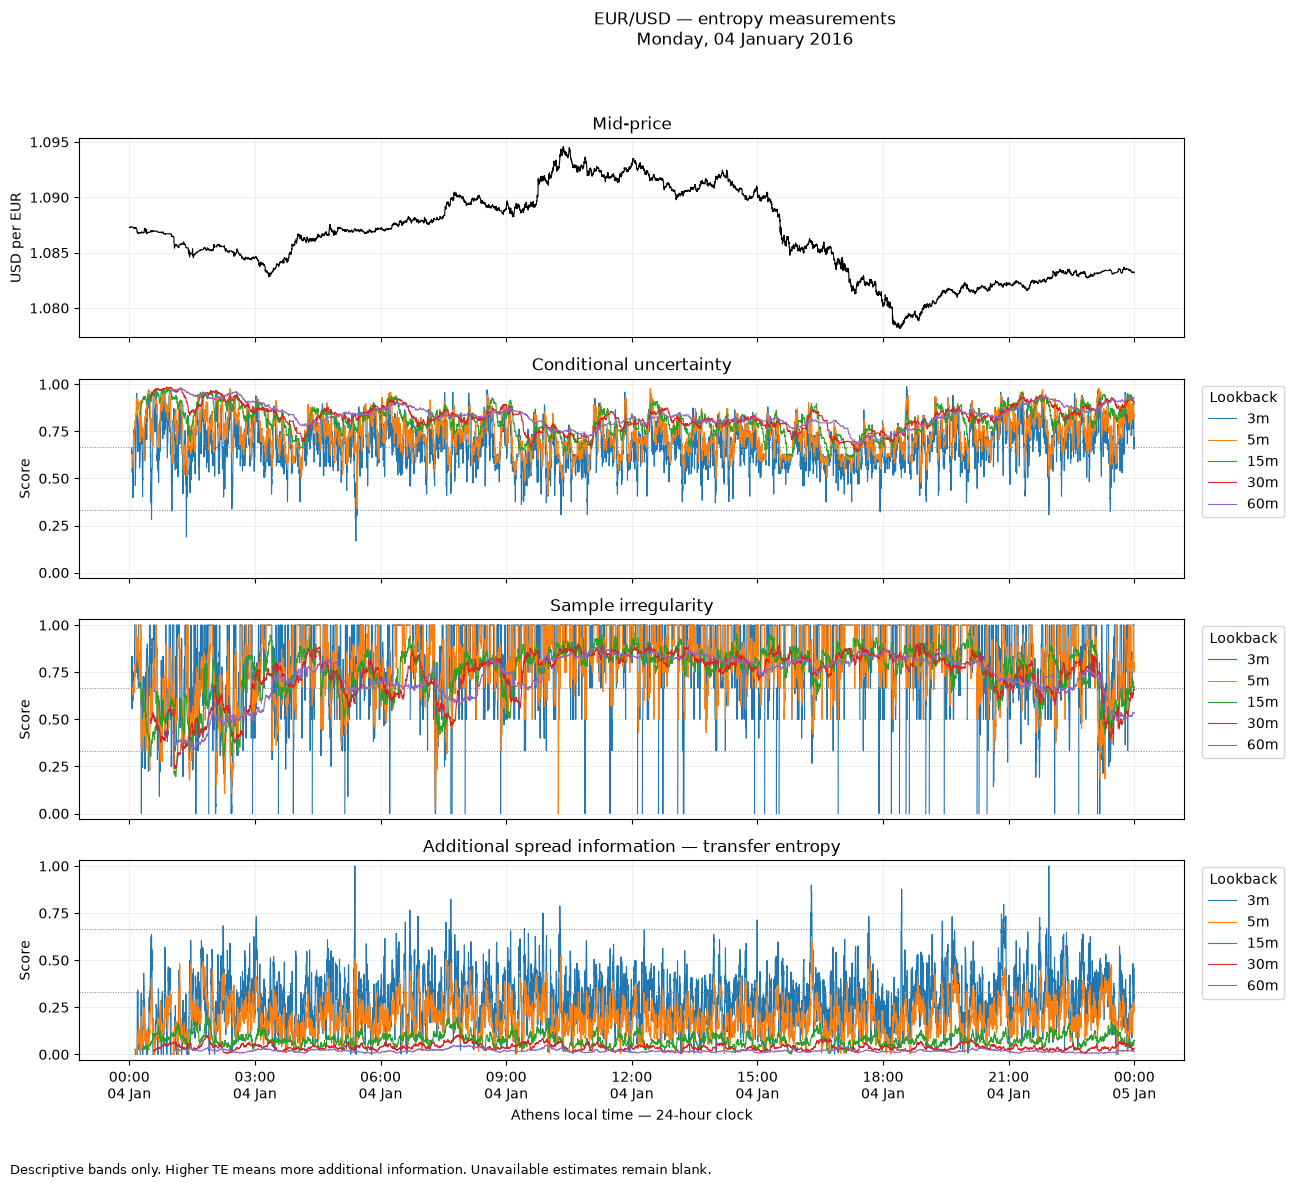

Figure: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\figures\entropy\entropy_04_v1\first_day_entropy.png


In [17]:
# Plot all five lookbacks.
# The chart uses measurement time.
# Replay must use the saved availability times.

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
from zoneinfo import ZoneInfo

first_feature_path = sorted(CTX["run"].glob("*.parquet"))[0]

with duckdb.connect() as figure_con:
    figure_con.read_parquet(
        str(first_feature_path), hive_partitioning=False
    ).create_view("first_day_entropy", replace=True)

    columns = ["sample_ns", "mid"]
    for key in entropy.WINDOWS:
        columns.extend([
            f"ce_score_{key}",
            f"sampen_score_{key}",
            f"te_fraction_{key}",
        ])

    plot_data = entropy.utilities.frame(
        figure_con,
        "SELECT " + ", ".join(columns)
        + " FROM first_day_entropy ORDER BY sample_ns",
    )

times = pd.to_datetime(
    plot_data["sample_ns"].astype("Int64"), unit="ns", utc=True
).dt.tz_convert("Europe/Athens")

def numeric(column):
    return plot_data[column].to_numpy(
        dtype=float, na_value=np.nan
    )

fig, axes = plt.subplots(
    4, 1, figsize=(15, 12), sharex=True
)

axes[0].plot(times, numeric("mid"), color="black", linewidth=0.8)
axes[0].set_ylabel("USD per EUR")
axes[0].set_title("Mid-price")

colors = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

for color, key in zip(colors, entropy.WINDOWS):
    axes[1].plot(
        times, numeric(f"ce_score_{key}"),
        label=key, color=color, linewidth=0.8,
    )
    axes[2].plot(
        times, numeric(f"sampen_score_{key}"),
        label=key, color=color, linewidth=0.8,
    )
    axes[3].plot(
        times, numeric(f"te_fraction_{key}"),
        label=key, color=color, linewidth=0.8,
    )

titles = [
    "Conditional uncertainty",
    "Sample irregularity",
    "Additional spread information — transfer entropy",
]

for axis, title in zip(axes[1:], titles):
    axis.set_title(title)
    axis.set_ylabel("Score")
    axis.set_ylim(-0.03, 1.03)
    axis.set_yticks([0, 0.25, 0.5, 0.75, 1])
    axis.axhline(1 / 3, color="gray", linestyle=":", linewidth=0.7)
    axis.axhline(2 / 3, color="gray", linestyle=":", linewidth=0.7)
    axis.legend(
        title="Lookback", loc="upper left", bbox_to_anchor=(1.01, 1)
    )

for axis in axes:
    axis.grid(alpha=0.2)

timezone = ZoneInfo("Europe/Athens")
axes[-1].xaxis.set_major_locator(
    mdates.HourLocator(byhour=range(0, 24, 3), tz=timezone)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%H:%M\n%d %b", tz=timezone)
)
axes[-1].set_xlabel("Athens local time — 24-hour clock")

fig.suptitle(
    "EUR/USD — entropy measurements\n"
    + times.iloc[0].strftime("%A, %d %B %Y")
)
fig.text(
    0.01, 0.01,
    "Descriptive bands only. Higher TE means more additional information. "
    "Unavailable estimates remain blank.",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.04, 0.87, 0.95])

FIGURE_PATH = CTX["figures"] / "first_day_entropy.png"
fig.savefig(FIGURE_PATH, dpi=160, bbox_inches="tight")
plt.show()

print("Figure:", FIGURE_PATH)

In [18]:
# Write the agreed decisions and current execution state.
# These records do not claim human acceptance of the new outputs.

assert SUMMARY["processed_prefix_machine_checks_passed"]

marker = f"notebook-04-{RUN_ID}"
scope = (
    "full available history"
    if SUMMARY["full_history_complete"]
    else f"prefix through {SUMMARY['processed_through']}"
)

entropy.utilities.write_section(
    ROOT / "docs" / "design_decisions.md",
    marker,
    f"""
## Notebook 04 — {RUN_ID}

Status: agreed definitions; execution-output human review pending.

- Inputs: Notebook 02 all-hours ten-second reconstructed market series.
- Lookbacks: 3, 5, 15, 30 and 60 minutes; update every ten seconds.
- Price symbols: down, unchanged, up.
- Conditional entropy uses the previous price symbol.
- Save normalized conditional uncertainty and residual-uncertainty diagnostic.
- Sample entropy uses length-two patterns extended to length three.
- Its tolerance is 20% of trailing population price-change SD.
- Save raw sample entropy and bounded irregularity score 1-A/B.
- Preserve undefined and infinite-raw cases with support counts.
- Transfer source: five-minute spread-change sign at the preceding step.
- Transfer target: following ten-second price-change sign.
- Condition transfer entropy on the preceding price-change sign.
- High TE denotes additional spread information.
- Labels use fixed thirds and are descriptive, not trading rules.
- Restart after unfilled missing periods; require fresh full support.
- Available excluded-hour data and eligible interpolation remain included.
- Preserve exact supporting availability timestamps.
- Numerical comparison tolerance: {entropy.MATCH_ATOL} pips.
- No full-history fitted bins, thresholds or normalizations.

Validation scope: {scope}.
Machine checks passed when this record was written.
Short-window statistical usefulness remains for empirical evaluation.

Provisional application:
Combine measurements with volatility, trend forecasts and MA distances.
No inventory, pricing or exit action is implemented here.

Later comparison:
After Notebook 06, compare a no-entropy baseline with each entropy candidate
on a one-month development experiment. Use matching observations and
chronological evaluation. Define success independently of each entropy score.
Confirm promising findings on later untouched data.
""",
)

entropy.utilities.write_section(
    ROOT / "CONTRIBUTIONS.md",
    marker,
    f"""
## Notebook 04 — {RUN_ID}

Raymond Fendi:
- Defined entropy's intended use in regime and risk-management research.
- Selected conditional, sample and transfer entropy as candidates.
- Selected 3, 5, 15, 30 and 60-minute lookbacks.
- Required ten-second updates and fresh history after missing periods.
- Selected five-minute spread evolution as the transfer-entropy source.
- Agreed 20% sample-entropy matching tolerance.
- Required decimal scores and low/medium/high descriptive labels.
- Agreed fixed-third label bands.
- Requested a later controlled comparison after regression is available.

OpenAI Codex:
- Prepared the notebook, calculation helper and validation code.
- Distinguished uncertainty, pattern irregularity and information transfer.
- Preserved interpolation eligibility and information availability.
- Added support diagnostics and bounded-memory processing.

Execution scope: {scope}.
Machine checks passed when this record was written.
Raymond's review of Notebook 04 execution outputs remains pending.
""",
)

entropy.utilities.write_section(
    ROOT / "README.md",
    marker,
    f"""
## Notebook 04 progress

Conditional entropy, sample entropy and spread-to-price transfer entropy
are implemented with ten-second updates and five agreed lookbacks.

Execution scope: {scope}.
Processed-prefix machine checks passed; human output review is pending.
Scores, support counts, labels and availability times are saved separately.
Statistical usefulness and trading applications remain for later evaluation.

Results pending execution and validation.
""",
)

state = f"""# Project state

- Notebooks 00, 01 and 01a: executed and reviewed.
- Notebook 02: full-history machine checks and Codex technical review completed.
- Notebook 03: full-history machine checks and Codex technical review completed.
- Current stage: Notebook 04 output review.
- Notebook 04 run: `{RUN_ID}`.
- Execution scope: {scope}.
- Machine checks: passed for the processed prefix.
- Notebook 04 human review: pending.

## Locations

- Input: `data/processed/sampling_02_v1/sampled_10s/`.
- Features: `outputs/features/entropy/{RUN_ID}/`.
- Reports: `reports/tables/entropy/{RUN_ID}/`.
- Figures: `reports/figures/entropy/{RUN_ID}/`.

## Outstanding matters

- Review entropy values, support, missing estimates, timing and runtime.
- Review the initial prefix before expanding processing.
- Exact historical provider closure completeness remains a limitation.
- Interpolation can introduce measured regularity.
- Descriptive entropy bands are not validated trading thresholds.
- Compare entropy candidates after regression is available.

## Next step

Review Notebook 04 saved outputs.
Then expand processing gradually using complete continuation cells.

## Outputs invalidated

None from the accepted upstream definitions.
Notebook 04 creates a separate versioned feature output.
Changed inputs or feature definitions require compatible regenerated outputs.
"""

(ROOT / "docs" / "project_state.md").write_text(
    state, encoding="utf-8"
)

print("Updated README.md, CONTRIBUTIONS.md and project records.")
print("Human review remains pending.")

Updated README.md, CONTRIBUTIONS.md and project records.
Human review remains pending.


In [19]:
# Final execution summary.
# Stop after this cell and return the outputs for review.

SUMMARY = dict(RESULTS["summary"])
SUMMARY["figure"] = FIGURE_PATH.relative_to(ROOT).as_posix()

entropy.fx.dump_json(
    CTX["tables"] / "execution_summary.json",
    SUMMARY,
)

print("NOTEBOOK_04_EXECUTION_SUMMARY")
print(json.dumps(SUMMARY, indent=2))

print("\nTables:", CTX["tables"])
print("Figure:", FIGURE_PATH)

print("""
STOP HERE.

Tell Codex: "Notebook 04 outputs ready."

The saved review material includes:
- execution_summary.json
- synthetic_checks.json
- synthetic_pattern_examples.csv
- completion_checks.json
- daily_summary.csv
- daily_checks.csv
- window_coverage.csv
- first_ready_windows.csv
- entropy_examples.csv
- delayed_examples.csv
- sample_no_match_examples.csv
- first_day_entropy.png

No screenshots or pasted tables are required.
""")

NOTEBOOK_04_EXECUTION_SUMMARY
{
  "notebook": "04_entropy.ipynb",
  "run_id": "entropy_04_v1",
  "fingerprint": "355d1378dab75041dc3a5af4a02aea55040be758a3a7eefa1a482c0d3ec6e841",
  "source_run_id": "sampling_02_v1",
  "source_fingerprint": "ad5235dc14f854d9f26ef04dd2c1fdf846faf05cff43eb9f84afccc229628e54",
  "mode": "prefix_review",
  "available_input_months": 130,
  "available_input_rows": 34032599,
  "processed_days": 1,
  "processed_through": "2016-01-04",
  "full_history_complete": false,
  "sample_rows": 8639,
  "priced_rows": 8639,
  "missing_price_rows": 0,
  "restart_rows": 1,
  "windows_minutes": [
    3,
    5,
    15,
    30,
    60
  ],
  "update_seconds": 10,
  "spread_measurement_seconds": 300,
  "sample_tolerance_fraction": 0.2,
  "synthetic_checks_passed": true,
  "nonzero_machine_checks": 0,
  "processed_prefix_machine_checks_passed": true,
  "full_history_machine_checks_passed": false,
  "human_review": "pending",
  "source_stability_check": "file sizes/times and che

In [20]:
# Expand the existing run through January 2016.
# Preserve January 4 and reuse its checkpoint.
# Add one targeted check for already-warmed long windows across a boundary.
# No feature definitions or upstream files change.

from pathlib import Path
import importlib
import json
import os
import sys

import numpy as np
import pandas as pd
import pyarrow as pa
from IPython.display import display

ROOT_HINT = None

candidates = (
    [Path(ROOT_HINT).expanduser().resolve()]
    if ROOT_HINT
    else [Path.cwd(), *Path.cwd().parents]
)

ROOT = next(
    (
        path for path in candidates
        if (path / "functions" / "entropy" / "market_entropy.py").is_file()
        and (path / "data").is_dir()
    ),
    None,
)

assert ROOT is not None, "Set ROOT_HINT to the repository folder."
ROOT = ROOT.resolve()
os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

importlib.invalidate_caches()
from functions.entropy import market_entropy as entropy
entropy = importlib.reload(entropy)

RUN_ID = "entropy_04_v1"
STOP_AFTER_DATE = "2016-01-31"

CTX = entropy.prepare(
    ROOT,
    run_id=RUN_ID,
    stop_after_date=STOP_AFTER_DATE,
    memory="2GB",
    threads=2,
)

initial_checkpoint = (
    CTX["run"] / "_checkpoints" / "2016-01-04.json"
)
assert initial_checkpoint.is_file()
initial_checkpoint_sha = entropy.utilities.sha(initial_checkpoint)

# The original boundary fixture included an outage.
# This additional fixture compares fully ready 60-minute results.

rng = np.random.default_rng(404)
length = 840
cut = 720

origin = int(pd.Timestamp(
    "2016-01-31 22:00:00", tz="Europe/Athens"
).value)

test_times = (
    origin
    + np.arange(length, dtype=np.int64) * entropy.STEP
)
test_available = test_times.copy()
test_available[cut - 1] += 120 * entropy.NS + 123

test_mid = (
    1.1
    + np.cumsum(rng.normal(0, 0.2, length)) * entropy.PIP
)
test_spread = (
    0.0001
    + 0.00003 * np.sin(np.arange(length) / 31)
)

test_interpolated = np.zeros(length, dtype=bool)
test_interpolated[cut - 1] = True
test_excluded = np.zeros(length, dtype=bool)
test_excluded[50:75] = True

test_source = pa.table({
    "sample_ns": test_times,
    "available_ns": test_available,
    "mid": test_mid,
    "spread": test_spread,
    "has_price": np.ones(length, dtype=bool),
    "is_interpolated": test_interpolated,
    "in_long_gap": np.zeros(length, dtype=bool),
    "project_excluded": test_excluded,
    "project_eligible": ~test_excluded,
})

whole, whole_checks, _ = entropy.compute(test_source)
entropy.validate_output(whole)

start = cut - entropy.MAX_PRIOR
tail, tail_checks, _ = entropy.compute(test_source.slice(start))

boundary_checks = {
    "whole_input_checks_zero": all(
        value == 0 for value in whole_checks.values()
    ),
    "tail_input_checks_zero": all(
        value == 0 for value in tail_checks.values()
    ),
    "longest_window_ready_at_boundary": bool(
        entropy.values(whole, "ready_te_60m")[cut]
    ),
    "all_ready_values_preserved_across_boundary": whole.slice(cut).equals(
        tail.slice(entropy.MAX_PRIOR),
        check_metadata=False,
    ),
}

assert all(boundary_checks.values()), boundary_checks

entropy.fx.dump_json(
    CTX["tables"] / "additional_boundary_checks.json",
    {
        "fingerprint": CTX["fingerprint"],
        "checks": boundary_checks,
        "passed": True,
    },
)

del test_source, whole, tail

# EXPENSIVE CELL — remaining available January days.
# Daily checkpoints allow interrupted processing to resume.

RESULTS = entropy.process(CTX)
SUMMARY = RESULTS["summary"]

assert entropy.utilities.sha(initial_checkpoint) == initial_checkpoint_sha
assert SUMMARY["processed_prefix_machine_checks_passed"]
assert SUMMARY["nonzero_machine_checks"] == 0
assert SUMMARY["processed_through"] >= STOP_AFTER_DATE

display(RESULTS["daily"])
display(RESULTS["coverage"])

print("January processing complete.")
print("Original January 4 checkpoint preserved.")
print("Reports:", CTX["tables"])

2016-01-04 resumed
2016-01-05 rows=8,640 seconds=9.5
2016-01-06 rows=8,640 seconds=10.3
2016-01-07 rows=8,640 seconds=9.3
2016-01-08 rows=8,640 seconds=9.0
2016-01-09 rows=8,640 seconds=0.3
2016-01-10 rows=8,640 seconds=0.2
2016-01-11 rows=8,640 seconds=8.4
2016-01-12 rows=8,640 seconds=8.6
2016-01-13 rows=8,640 seconds=8.4
2016-01-14 rows=8,640 seconds=8.3
2016-01-15 rows=8,640 seconds=8.3
2016-01-16 rows=8,640 seconds=0.3
2016-01-17 rows=8,640 seconds=0.2
2016-01-18 rows=8,640 seconds=8.4
2016-01-19 rows=8,640 seconds=8.4
2016-01-20 rows=8,640 seconds=8.2
2016-01-21 rows=8,640 seconds=8.2
2016-01-22 rows=8,640 seconds=8.2
2016-01-23 rows=8,640 seconds=0.3
2016-01-24 rows=8,640 seconds=0.2
2016-01-25 rows=8,640 seconds=8.1
2016-01-26 rows=8,640 seconds=8.3
2016-01-27 rows=8,640 seconds=8.3
2016-01-28 rows=8,640 seconds=8.3
2016-01-29 rows=8,640 seconds=8.2
2016-01-30 rows=8,640 seconds=0.3
2016-01-31 rows=8,640 seconds=0.2


,date,year_month,sample_rows,first_ns,last_ns,priced_rows,missing_price_rows,restart_rows,ce_ready_3m_rows,project_ce_ready_3m_rows,...,ce_ready_60m_rows,project_ce_ready_60m_rows,sampen_defined_60m_rows,sampen_no_matches_60m_rows,sampen_infinite_raw_60m_rows,te_ready_60m_rows,te_defined_60m_rows,project_te_defined_60m_rows,calculation_seconds_60m,processing_seconds
0,2016-01-04,2016-01,8639,1451858410000000000,1451944790000000000,8639,0,1,8621,7560,...,8279,7560,8279,0,0,8250,8250,7560,4.335008,9.491808
1,2016-01-05,2016-01,8640,1451944800000000000,1452031190000000000,8640,0,0,8640,7560,...,8640,7560,8640,0,0,8640,8640,7560,4.602953,9.473116
2,2016-01-06,2016-01,8640,1452031200000000000,1452117590000000000,8640,0,0,8640,7560,...,8640,7560,8640,0,0,8640,8640,7560,5.239290,10.252791
3,2016-01-07,2016-01,8640,1452117600000000000,1452203990000000000,8640,0,0,8640,7560,...,8640,7560,8640,0,0,8640,8640,7560,4.539048,9.279337
4,2016-01-08,2016-01,8640,1452204000000000000,1452290390000000000,8638,2,0,8638,7560,...,8638,7560,8638,0,0,8638,8638,7560,4.366274,9.047236
5,2016-01-09,2016-01,8640,1452290400000000000,1452376790000000000,0,8640,0,0,0,...,0,0,0,0,0,0,0,0,0.036368,0.319878
6,2016-01-10,2016-01,8640,1452376800000000000,1452463190000000000,0,8640,0,0,0,...,0,0,0,0,0,0,0,0,0.020994,0.168713
7,2016-01-11,2016-01,8640,1452463200000000000,1452549590000000000,8639,1,1,8621,7560,...,8279,7560,8279,0,0,8250,8250,7560,4.004868,8.397508
8,2016-01-12,2016-01,8640,1452549600000000000,1452635990000000000,8640,0,0,8640,7560,...,8640,7560,8640,0,0,8640,8640,7560,4.179897,8.575269
9,2016-01-13,2016-01,8640,1452636000000000000,1452722390000000000,8640,0,0,8640,7560,...,8640,7560,8640,0,0,8640,8640,7560,4.036817,8.369660


,window,price_changes_required,transition_pairs_per_complete_window,ce_first_ready_seconds_after_fresh_open,te_first_ready_seconds_after_fresh_open,ce_ready_rows,project_ce_ready_rows,sampen_defined_rows,sampen_no_match_rows,sampen_infinite_raw_rows,te_ready_rows,te_defined_rows,project_te_defined_rows,calculation_seconds_including_context
0,3m,18,17,180,470,172718,151200,144324,28394,90321,172602,172593,151197,16.034396
1,5m,30,29,300,590,172670,151200,171470,1200,62256,172554,172554,151200,16.244361
2,15m,90,89,900,1190,172430,151200,172430,0,261,172314,172314,151200,21.271389
3,30m,180,179,1800,2090,172070,151200,172070,0,0,171954,171954,151200,35.349393
4,60m,360,359,3600,3890,171350,151200,171350,0,0,171234,171234,151200,81.783819


January processing complete.
Original January 4 checkpoint preserved.
Reports: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\tables\entropy\entropy_04_v1


In [21]:
# Review January support separately for all hours and project-eligible rows.
# Export examples around an actual restart and delayed availability.

import duckdb

january_paths = [
    str(path)
    for path in sorted(CTX["run"].glob("2016-01-*.parquet"))
]
assert january_paths

support_rows = []

with duckdb.connect(config={
    "memory_limit": "2GB",
    "threads": 2,
}) as con:

    con.read_parquet(
        january_paths, hive_partitioning=False
    ).create_view("january_entropy", replace=True)

    for scope, condition in {
        "all_hours": "TRUE",
        "project_eligible": "project_eligible",
    }.items():
        for key in entropy.WINDOWS:
            row = entropy.utilities.frame(con, f"""
                SELECT
                    '{scope}' AS scope,
                    '{key}' AS window,
                    count(*) FILTER (
                        WHERE ready_price_{key}
                    ) AS complete_price_windows,
                    count(*) FILTER (
                        WHERE sampen_score_{key} IS NOT NULL
                    ) AS sample_defined,
                    count(*) FILTER (
                        WHERE sampen_status_{key} = 'no_matches'
                    ) AS sample_no_matches,
                    count(*) FILTER (
                        WHERE sampen_status_{key} = 'infinite_raw'
                    ) AS sample_score_one,
                    min(sampen_B_{key}) FILTER (
                        WHERE sampen_B_{key} > 0
                    ) AS minimum_positive_matching_pairs,
                    median(sampen_B_{key}) FILTER (
                        WHERE sampen_B_{key} > 0
                    ) AS median_positive_matching_pairs,
                    count(*) FILTER (
                        WHERE ready_te_{key}
                    ) AS complete_transfer_windows,
                    count(*) FILTER (
                        WHERE te_fraction_{key} IS NOT NULL
                    ) AS transfer_defined
                FROM january_entropy
                WHERE {condition}
            """)
            support_rows.append(row)

    delayed = entropy.utilities.frame(con, """
        SELECT
            sample_ns,
            ce_available_ns_3m,
            te_available_ns_3m,
            (ce_available_ns_3m - sample_ns) / 1e9
                AS ce_delay_seconds,
            (te_available_ns_3m - sample_ns) / 1e9
                AS te_delay_seconds,
            ce_score_3m,
            sampen_score_3m,
            te_fraction_3m,
            interp_change_fraction_3m,
            project_eligible
        FROM january_entropy
        WHERE ready_te_3m
        ORDER BY te_delay_seconds DESC, sample_ns
        LIMIT 12
    """)

    restarts = entropy.utilities.frame(con, """
        SELECT sample_ns
        FROM january_entropy
        WHERE restart
        ORDER BY sample_ns
    """)

    restart_example = pd.DataFrame()
    if len(restarts) > 1:
        restart_ns = int(restarts["sample_ns"].iloc[1])
        restart_example = entropy.utilities.frame(con, f"""
            SELECT
                sample_ns,
                fresh_changes_capped,
                ready_price_3m,
                ready_te_3m,
                ready_price_15m,
                ready_te_15m,
                ready_price_60m,
                ready_te_60m,
                ce_score_3m,
                sampen_score_3m,
                te_fraction_3m,
                project_eligible
            FROM january_entropy
            WHERE sample_ns BETWEEN
                {restart_ns}
                AND {restart_ns + 389 * entropy.STEP}
              AND fresh_changes_capped IN (
                  0, 17, 18, 29, 30, 46, 47,
                  89, 90, 118, 119, 179, 180,
                  208, 209, 359, 360, 388, 389
              )
            ORDER BY sample_ns
        """)

support = pd.concat(support_rows, ignore_index=True)

denominator = support["complete_price_windows"].replace(0, pd.NA)
support["sample_no_match_percent"] = (
    100 * support["sample_no_matches"] / denominator
)
support["sample_score_one_percent"] = (
    100 * support["sample_score_one"] / denominator
)

delayed = entropy.utilities.display_times(
    delayed,
    ["sample_ns", "ce_available_ns_3m", "te_available_ns_3m"],
)
restarts = entropy.utilities.display_times(
    restarts, ["sample_ns"]
)
restart_example = entropy.utilities.display_times(
    restart_example, ["sample_ns"]
)

for filename, table in {
    "january_support_by_scope.csv": support,
    "january_delayed_examples.csv": delayed,
    "january_restarts.csv": restarts,
    "january_restart_example.csv": restart_example,
}.items():
    table.to_csv(CTX["tables"] / filename, index=False)

print("SUPPORT BY WINDOW AND RESEARCH SCOPE")
display(support)

print("OBSERVED RESTARTS")
display(restarts)

print("FRESH WARM-UP AFTER A RESTART")
display(restart_example)

print("DELAYED AVAILABILITY")
display(delayed)

SUPPORT BY WINDOW AND RESEARCH SCOPE


,scope,window,complete_price_windows,sample_defined,sample_no_matches,sample_score_one,minimum_positive_matching_pairs,median_positive_matching_pairs,complete_transfer_windows,transfer_defined,sample_no_match_percent,sample_score_one_percent
0,all_hours,3m,172718,144324,28394,90321,1,2.0,172602,172593,16.439514,52.293913
1,all_hours,5m,172670,171470,1200,62256,1,8.0,172554,172554,0.694967,36.054902
2,all_hours,15m,172430,172430,0,261,13,93.0,172314,172314,0.0,0.151366
3,all_hours,30m,172070,172070,0,0,97,410.0,171954,171954,0.0,0.0
4,all_hours,60m,171350,171350,0,0,469,1776.0,171234,171234,0.0,0.0
5,project_eligible,3m,151200,124299,26901,82625,1,2.0,151200,151197,17.791667,54.646164
6,project_eligible,5m,151200,150040,1160,59436,1,7.0,151200,151200,0.767196,39.309524
7,project_eligible,15m,151200,151200,0,259,13,84.0,151200,151200,0.0,0.171296
8,project_eligible,30m,151200,151200,0,0,97,372.0,151200,151200,0.0,0.0
9,project_eligible,60m,151200,151200,0,0,469,1638.0,151200,151200,0.0,0.0


OBSERVED RESTARTS


,sample_ns,sample_athens
0,1451858410000000000,2016-01-04 00:00:10+02:00
1,1452463210000000000,2016-01-11 00:00:10+02:00
2,1453068030000000000,2016-01-18 00:00:30+02:00
3,1453672810000000000,2016-01-25 00:00:10+02:00


FRESH WARM-UP AFTER A RESTART


,sample_ns,fresh_changes_capped,ready_price_3m,ready_te_3m,ready_price_15m,ready_te_15m,ready_price_60m,ready_te_60m,ce_score_3m,sampen_score_3m,te_fraction_3m,project_eligible,sample_athens
0,1452463210000000000,0,False,False,False,False,False,False,<NA>,<NA>,<NA>,False,2016-01-11 00:00:10+02:00
1,1452463380000000000,17,False,False,False,False,False,False,<NA>,<NA>,<NA>,False,2016-01-11 00:03:00+02:00
2,1452463390000000000,18,True,False,False,False,False,False,0.547606,1.0,<NA>,False,2016-01-11 00:03:10+02:00
3,1452463500000000000,29,True,False,False,False,False,False,0.748386,1.0,<NA>,False,2016-01-11 00:05:00+02:00
4,1452463510000000000,30,True,False,False,False,False,False,0.720964,1.0,<NA>,False,2016-01-11 00:05:10+02:00
5,1452463670000000000,46,True,False,False,False,False,False,0.592263,0.481481,<NA>,False,2016-01-11 00:07:50+02:00
6,1452463680000000000,47,True,True,False,False,False,False,0.552169,0.461538,0.0,False,2016-01-11 00:08:00+02:00
7,1452464100000000000,89,True,True,False,False,False,False,0.672344,0.259259,0.0,False,2016-01-11 00:15:00+02:00
8,1452464110000000000,90,True,True,True,False,False,False,0.5658,0.285714,0.0,False,2016-01-11 00:15:10+02:00
9,1452464390000000000,118,True,True,True,False,False,False,0.64158,0.833333,0.174831,False,2016-01-11 00:19:50+02:00


DELAYED AVAILABILITY


,sample_ns,ce_available_ns_3m,te_available_ns_3m,ce_delay_seconds,te_delay_seconds,ce_score_3m,sampen_score_3m,te_fraction_3m,interp_change_fraction_3m,project_eligible,sample_athens,ce_available_athens_3m,te_available_athens_3m
0,1453148260000000000,1453148444515000000,1453148444515000000,184.515,184.515,0.74753,0.666667,0.366743,0.222222,True,2016-01-18 22:17:40+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00
1,1453148270000000000,1453148444515000000,1453148444515000000,174.515,174.515,0.720964,0.666667,0.260548,0.277778,True,2016-01-18 22:17:50+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00
2,1453156640000000000,1453156805617000000,1453156805617000000,165.617,165.617,0.324172,0.394737,0.32451,0.944444,False,2016-01-19 00:37:20+02:00,2016-01-19 00:40:05.617000+02:00,2016-01-19 00:40:05.617000+02:00
3,1453148280000000000,1453148444515000000,1453148444515000000,164.515,164.515,0.720964,0.75,0.260548,0.333333,True,2016-01-18 22:18:00+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00
4,1453156650000000000,1453156805617000000,1453156805617000000,155.617,155.617,0.324172,0.470588,0.357768,0.944444,False,2016-01-19 00:37:30+02:00,2016-01-19 00:40:05.617000+02:00,2016-01-19 00:40:05.617000+02:00
5,1453148290000000000,1453148444515000000,1453148444515000000,154.515,154.515,0.700725,0.666667,0.258498,0.388889,True,2016-01-18 22:18:10+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00
6,1453156660000000000,1453156805617000000,1453156805617000000,145.617,145.617,0.324172,0.5,0.399502,0.944444,False,2016-01-19 00:37:40+02:00,2016-01-19 00:40:05.617000+02:00,2016-01-19 00:40:05.617000+02:00
7,1453148300000000000,1453148444515000000,1453148444515000000,144.515,144.515,0.683125,0.5,0.328247,0.444444,True,2016-01-18 22:18:20+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00
8,1453156670000000000,1453156805617000000,1453156805617000000,135.617,135.617,0.324172,0.464286,0.399502,0.944444,False,2016-01-19 00:37:50+02:00,2016-01-19 00:40:05.617000+02:00,2016-01-19 00:40:05.617000+02:00
9,1453148310000000000,1453148444515000000,1453148444515000000,134.515,134.515,0.683125,0.4,0.328247,0.5,True,2016-01-18 22:18:30+02:00,2016-01-18 22:20:44.515000+02:00,2016-01-18 22:20:44.515000+02:00


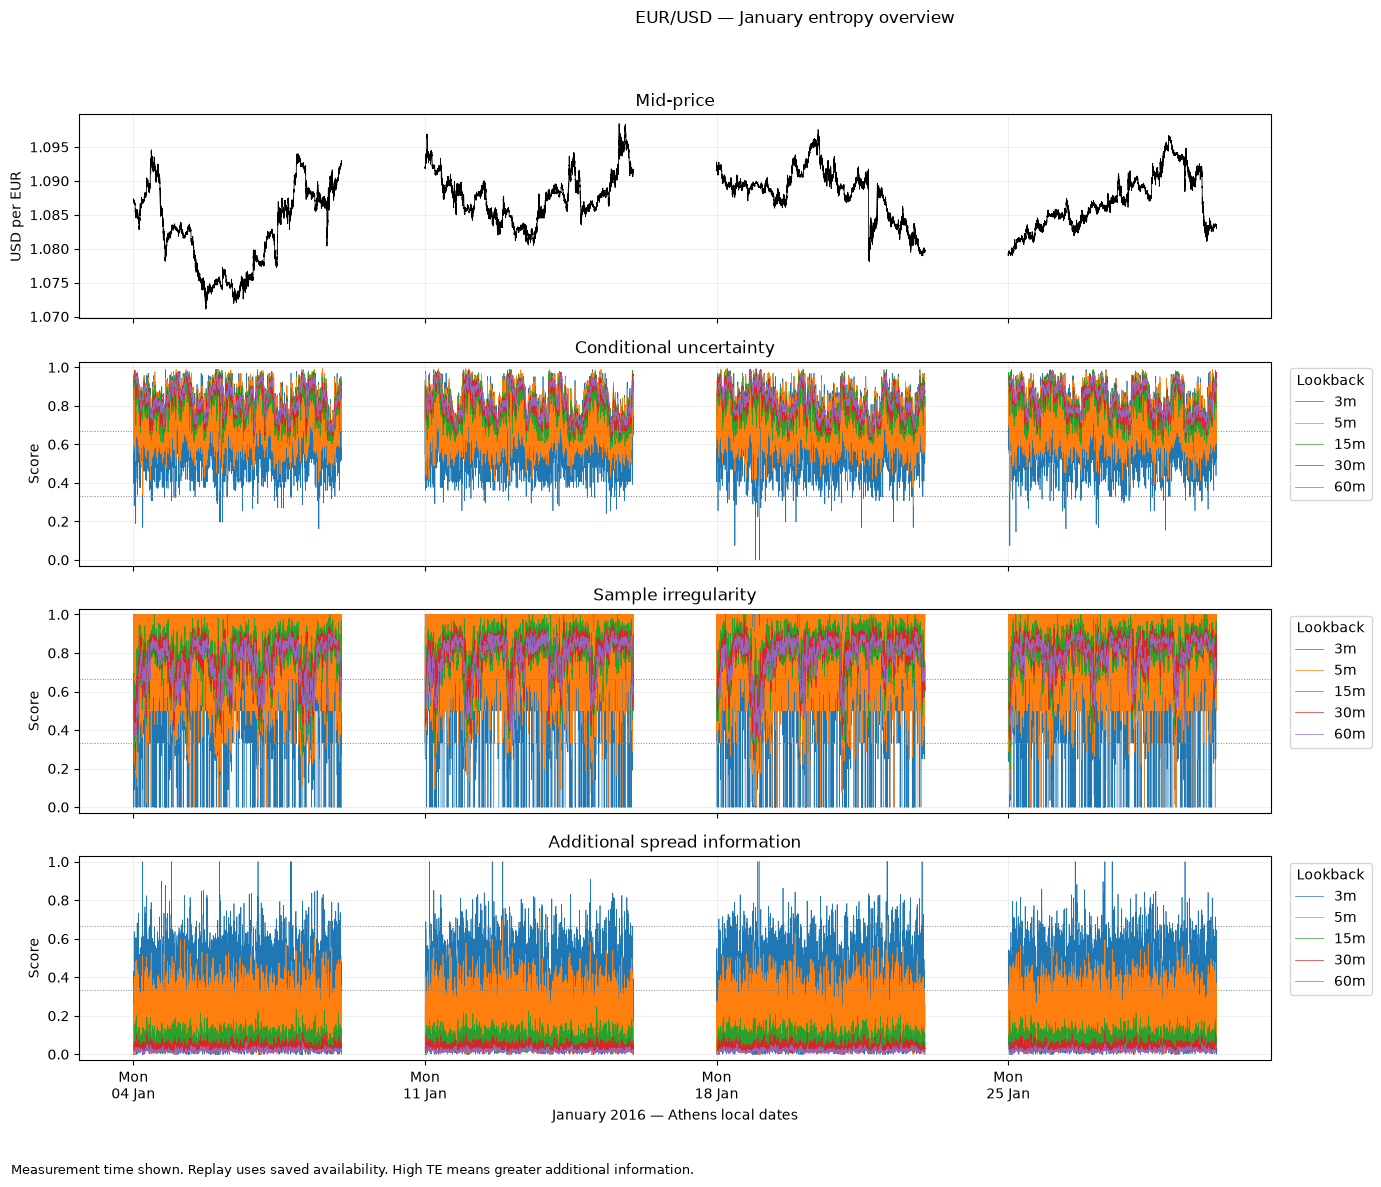

Figure: C:\Users\Ijzd4\Desktop\Inventory-Aware FX Pricing and Hedging Simulator\reports\figures\entropy\entropy_04_v1\january_entropy.png


In [22]:
# Save a January overview with clear calendar labels.
# Missing estimates and missing prices remain blank.

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo

columns = ["sample_ns", "mid"]
for key in entropy.WINDOWS:
    columns.extend([
        f"ce_score_{key}",
        f"sampen_score_{key}",
        f"te_fraction_{key}",
    ])

with duckdb.connect(config={"memory_limit": "2GB", "threads": 2}) as con:
    con.read_parquet(
        january_paths, hive_partitioning=False
    ).create_view("january_plot", replace=True)

    plot_data = entropy.utilities.frame(
        con,
        "SELECT " + ", ".join(columns)
        + " FROM january_plot ORDER BY sample_ns",
    )

times = pd.to_datetime(
    plot_data["sample_ns"].astype("Int64"), unit="ns", utc=True
).dt.tz_convert("Europe/Athens")

def january_numeric(column):
    return plot_data[column].to_numpy(
        dtype=float, na_value=np.nan
    )

fig, axes = plt.subplots(
    4, 1, figsize=(16, 12), sharex=True
)

axes[0].plot(
    times, january_numeric("mid"),
    color="black", linewidth=0.6,
)
axes[0].set_title("Mid-price")
axes[0].set_ylabel("USD per EUR")

colors = [
    "tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"
]

families = [
    ("ce_score", "Conditional uncertainty"),
    ("sampen_score", "Sample irregularity"),
    ("te_fraction", "Additional spread information"),
]

for axis, (prefix, title) in zip(axes[1:], families):
    for color, key in zip(colors, entropy.WINDOWS):
        axis.plot(
            times,
            january_numeric(f"{prefix}_{key}"),
            label=key,
            color=color,
            linewidth=0.5,
            rasterized=True,
        )

    axis.set_title(title)
    axis.set_ylabel("Score")
    axis.set_ylim(-0.03, 1.03)
    axis.axhline(1 / 3, color="gray", linestyle=":", linewidth=0.7)
    axis.axhline(2 / 3, color="gray", linestyle=":", linewidth=0.7)
    axis.legend(
        title="Lookback",
        loc="upper left",
        bbox_to_anchor=(1.01, 1),
    )

for axis in axes:
    axis.grid(alpha=0.2)

timezone = ZoneInfo("Europe/Athens")
axes[-1].xaxis.set_major_locator(
    mdates.WeekdayLocator(byweekday=mdates.MO, tz=timezone)
)
axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%a\n%d %b", tz=timezone)
)
axes[-1].set_xlabel("January 2016 — Athens local dates")

fig.suptitle("EUR/USD — January entropy overview")
fig.text(
    0.01, 0.01,
    "Measurement time shown. Replay uses saved availability. "
    "High TE means greater additional information.",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.04, 0.87, 0.95])

JANUARY_FIGURE = CTX["figures"] / "january_entropy.png"
fig.savefig(JANUARY_FIGURE, dpi=160, bbox_inches="tight")
plt.show()

del plot_data

print("Figure:", JANUARY_FIGURE)